# Laboratorio 15 - GNN y MACE para sistemas físicos

En este laboratorio entrenamos redes de paso de mensajes sobre dos sistemas físicos y usamos un potencial interatómico aprendido, MACE-MP-0.

**Antes de empezar:** active la GPU de Colab. Con el menú en español: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4 → Guardar*. Con el menú en inglés: *Runtime → Change runtime type → T4 GPU → Save*. Las celdas marcadas `# COMPLETAR` son las suyas; cada una viene con una prueba que dice si quedó bien. Los ejercicios previos traen su solución en una celda oculta (*Mostrar código*); úsela solo para comprobar. En la sesión 5, después de una pausa, Colab habrá olvidado lo que se ejecutó en la sesión 4: vuelva a ejecutar la **Preparación** y siga directamente con la parte A1; las partes A y B no dependen de los ejercicios previos. La descarga de los datos de A2 tarda unos minutos: ejecútela al empezar, mientras trabaja en A1.

$\require{mhchem}$

# Preparación

En Colab, PyTorch ya viene instalado. Instalamos PyTorch Geometric, MACE (que trae ASE) y `spglib`, que identifica el grupo espacial de un cristal. Si Colab pide reiniciar el entorno después de la instalación, hágalo y siga desde la celda de librerías.

In [1]:
%pip install -q torch_geometric mace-torch spglib tabulate

In [2]:
# === Librerías estándar de Python ===
import gzip
import json
import random
import warnings
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import requests
import re

# === Ciencia de datos y visualización ===
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import networkx as nx
from scipy.spatial import cKDTree

# === Machine Learning Clásico (Scikit-Learn) ===
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# === PyTorch y GNNs (PyTorch Geometric) ===
import torch
import torch.nn as nn
from torch.nn import functional as fn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import CGConv, GCNConv, global_add_pool, global_mean_pool
from torch_geometric.utils import from_networkx, to_dense_adj, to_undirected, to_networkx

# === Física de materiales y cristalografía (ASE y spglib) ===
from ase import Atoms
from ase.build import bulk
from ase.eos import EquationOfState
from ase.neighborlist import neighbor_list
from ase.units import GPa
import spglib
from mace.calculators import mace_mp

# === Configuración de Semillas para Reproducibilidad ===
SEED = 137
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# === Funciones auxiliares y Visualización ===
from IPython.display import HTML, display, Markdown
from tabulate import tabulate
from tqdm.notebook import tqdm

def dMarkdown(text):
    """
    Muestra texto enriquecido en formato Markdown en el notebook.
    Parámetros:
    text (str): Cadena de caracteres formateada en Markdown.
    """
    display(Markdown(text))

def dM_table(datos_tabla, headers):
    """
    Toma una lista de datos y cabeceras, y muestra una tabla formateada en Markdown.
    Parámetros:
    datos_tabla (list of lists): Filas con la información a mostrar.
    headers (list of str): Nombres de las columnas de la tabla.
    """
    tabla_md = tabulate(
        datos_tabla,
        headers=headers,
        tablefmt="pipe"
    )
    dMarkdown(tabla_md)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


In [3]:
# Determinar de forma dinámica si se cuenta con aceleración por hardware (GPU CUDA)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
detalles_gpu = ""
if dispositivo == "cuda":
    # Extraer información y memoria de la tarjeta gráfica activa
    nombre_gpu = torch.cuda.get_device_name(0)
    memoria_total = torch.cuda.get_device_properties(0).total_memory/1e9
    detalles_gpu = f"\n**GPU:** {nombre_gpu} ({memoria_total:.1f} GB)"

# Mostrar el reporte del dispositivo usando formato enriquecido de Markdown
dMarkdown(f"""
### Dispositivo de entrenamiento:
* **Tipo:** {dispositivo.upper()}{detalles_gpu}
""")

# Inicializar el calculador MACE-MP-0 con precisión float64
# Silenciamos las advertencias de deprecación/carga que pudieran ensuciar la salida del bloque
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=UserWarning)
    warnings.filterwarnings("ignore", category=FutureWarning)
    calc = mace_mp(model="medium", default_dtype="float64", device=dispositivo)



### Dispositivo de entrenamiento:
* **Tipo:** CUDA
**GPU:** Tesla T4 (15.6 GB)


Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


# Ejercicios previos (al final de la sesión 4)

Cuatro ejercicios cortos que preparan las partes A2 y B. Se hacen en clase con el docente; lo que no se termine se completa antes del laboratorio.

## Previo 1. Lectura del grafo: ¿suma o media?

Para predecir una propiedad del grafo completo se reúnen los estados de los nodos con una función invariante: la suma, la media o el máximo. Complete `lectura` y aplíquela a un triángulo y a dos copias de él, con el grado de cada nodo como estado.

In [4]:
# Función que actúa como operación de lectura global (readout) reduciendo atributos de nodos
def lectura(h):
    """Suma, media y máximo de los estados h (un arreglo con un valor por nodo)."""
    return np.sum(h), np.mean(h), np.max(h)

# Crear estructuras de prueba simples utilizando la librería NetworkX
triangulo = nx.cycle_graph(3)
dos_triangulos = nx.disjoint_union(triangulo, triangulo)
resultados_tabla = []

# Iterar sobre las estructuras para evaluar cómo responden los distintos operadores de agregación
for nombre, G in [
    ("Un triángulo", triangulo),
    ("Dos triángulos", dos_triangulos)
    ]:
    # Obtener el grado de cada nodo en el grafo como atributo o estado local h
    h = np.array([grado for _, grado in G.degree()])

    # Calcular las agregaciones global de suma, media y máximo
    s, m, x = lectura(h)

    # Almacenar las métricas formateadas para construir la tabla comparativa
    resultados_tabla.append([nombre, f"{s:.0f}", f"{m:.2f}", f"{x:.0f}"])

# Mostrar los resultados del análisis en una tabla Markdown clara y estructurada
dM_table(resultados_tabla, headers=["Estructura", "Suma", "Media", "Máximo"])

| Estructura     |   Suma |   Media |   Máximo |
|:---------------|-------:|--------:|---------:|
| Un triángulo   |      6 |       2 |        2 |
| Dos triángulos |     12 |       2 |        2 |

**Responda:**

* **¿Cuál de las tres lecturas distingue un grafo de dos copias de sí mismo?**
  La lectura de **suma** es la única que distingue un grafo de dos copias de sí mismo, ya que el valor total se duplicará.

* **¿La energía de un cristal es extensiva?**
  **Sí**, la energía es una propiedad extensiva, depende de la cantidad de materia (el tamaño del sistema).

* **¿El módulo de compresibilidad es intensivo?**
  **Sí**, el módulo de compresibilidad es una propiedad intensiva, es inherente al material y no depende del tamaño de la celda.

* **¿Qué lectura usaría para cada una?**
  * Para la energía (extensiva) usaría la **suma**.
  * Para el módulo de compresibilidad (intensivo) usaría la **media**.

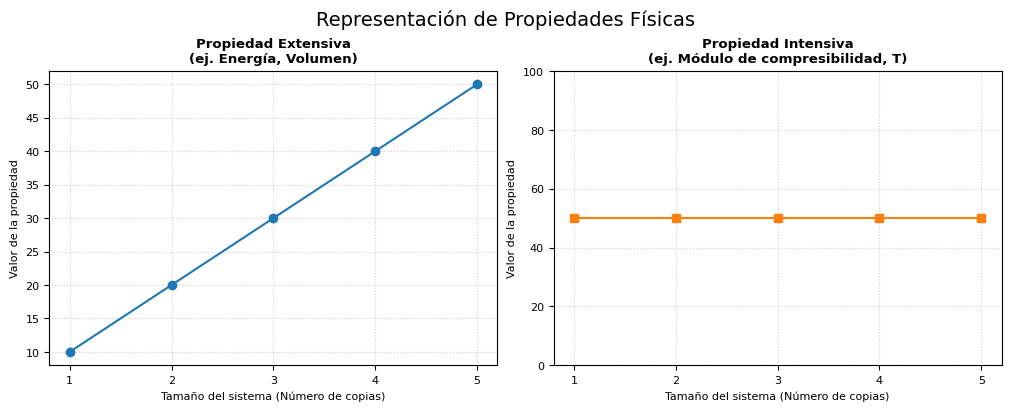

In [5]:
# Crear datos simulados para mostrar el concepto
tamaños = np.array([1, 2, 3, 4, 5])

# Propiedad extensiva (Ej: Energía, Volumen)
# Aumenta proporcionalmente con el tamaño del sistema
propiedad_extensiva = tamaños * 10

# Propiedad intensiva (Ej: Módulo de compresibilidad, Temperatura, Densidad)
# Se mantiene constante independientemente del tamaño del sistema
propiedad_intensiva = np.full_like(tamaños, 50)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')

# Gráfico para propiedad extensiva
ax1.plot(tamaños, propiedad_extensiva, marker='o', color='tab:blue', linestyle='-')
ax1.set_title('Propiedad Extensiva\n(ej. Energía, Volumen)', fontweight='bold')
ax1.set_xlabel('Tamaño del sistema (Número de copias)')
ax1.set_ylabel('Valor de la propiedad')
ax1.set_xticks(tamaños)
ax1.grid(True, linestyle=':', alpha=0.6)

# Gráfico para propiedad intensiva
ax2.plot(tamaños, propiedad_intensiva, marker='s', color='tab:orange', linestyle='-')
ax2.set_title('Propiedad Intensiva\n(ej. Módulo de compresibilidad, T)', fontweight='bold')
ax2.set_xlabel('Tamaño del sistema (Número de copias)')
ax2.set_ylabel('Valor de la propiedad')
ax2.set_ylim(0, 100)
ax2.set_xticks(tamaños)
ax2.grid(True, linestyle=':', alpha=0.6)

fig.suptitle('Representación de Propiedades Físicas', fontsize=14)
plt.show()

## Previo 2. Mini-lotes: una matriz diagonal por bloques

PyG entrena con varios grafos a la vez uniéndolos en un solo grafo desconectado. Construimos tres grafos pequeños, con el grado como atributo de cada nodo, y los juntamos en un lote con `DataLoader`.

In [6]:
# Función auxiliar para generar un grafo completo K4 al que se le remueve una arista
def k4_menos_arista():
    G = nx.complete_graph(4)
    G.remove_edge(0, 2)
    return G

# Definir una lista de grafos de prueba con distintas topologías
grafos = [nx.cycle_graph(3), nx.cycle_graph(6), k4_menos_arista()]
lista = []

# Convertir cada grafo de NetworkX a un objeto Data de PyTorch Geometric (PyG)
for G in grafos:
    # from_networkx extrae automáticamente la conectividad de las aristas (edge_index)
    dato = from_networkx(G)
    # Definir el atributo de nodo 'x' como el grado de cada vértice
    dato.x = torch.tensor([[float(G.degree(u))] for u in G.nodes()])
    lista.append(dato)

# Empaquetar los grafos en un único mini-lote (batch) desconectado
lote = next(iter(DataLoader(lista, batch_size=3)))

# Mostrar el resumen del lote y el vector descriptor de pertenencia de cada nodo ('batch')
dMarkdown(f"`{lote}`<br>**batch** = `{lote.batch.tolist()}`")

`DataBatch(edge_index=[2, 28], num_nodes=13, x=[13, 1], batch=[13], ptr=[4])`<br>**batch** = `[0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2]`

Complete la celda siguiente: obtenga la matriz de adyacencia densa del lote con `to_dense_adj(lote.edge_index)[0]` y dibújela con `plt.imshow`; luego calcule la lectura de media de cada grafo con `global_mean_pool(lote.x, lote.batch)` y compruebe que coincide con el grado medio de cada uno.

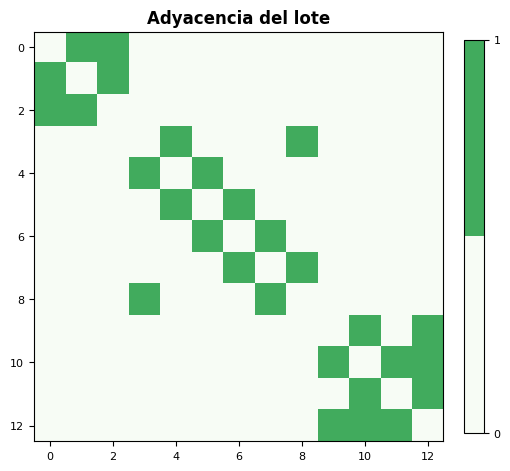

### Resultados de lectura de la agregación global del lote

| Grupo                        |   Suma |   Media |   Máximo |
|:-----------------------------|-------:|--------:|---------:|
| Lote total (Nodos agrupados) |     28 |  2.1538 |        3 |

### Medias de atributos por grafo dentro del lote

| Estructura   |   Media global_mean_pool |
|:-------------|-------------------------:|
| Grafo 0      |                      2   |
| Grafo 1      |                      2   |
| Grafo 2      |                      2.5 |

In [7]:
# Crear la figura y el eje con un diseño ajustado
fig, ax = plt.subplots(figsize=(5, 5), layout='constrained')
# Definir mapa de colores discreto para distinguir la ausencia (0) o presencia (1) de aristas
cmap_discreto = plt.matplotlib.colors.ListedColormap(['#f7fcf5', '#41ab5d'])
# Obtener la matriz densa de adyacencia a partir del índice de aristas del lote y graficarla
im = ax.imshow(to_dense_adj(lote.edge_index)[0], cmap=cmap_discreto)
ax.set_title("Adyacencia del lote", fontsize=12, fontweight='bold')
fig.colorbar(im, ax=ax, shrink=0.8, ticks=[0, 1])
plt.show()

# Calcular la media de los atributos por grafo de forma independiente en el lote
medias_pool = global_mean_pool(lote.x, lote.batch).flatten().tolist()
# Evaluar las métricas de lectura considerando todos los nodos unificados
suma, media, maximo = lectura(lote.x.flatten().numpy())

# Reporte de resultados en tablas Markdown
dMarkdown("### Resultados de lectura de la agregación global del lote")
dM_table([
    ["Lote total (Nodos agrupados)",
     f"{suma:.2f}",
     f"{media:.4f}",
     f"{maximo:.2f}"]
    ], headers=["Grupo", "Suma", "Media", "Máximo"])

dMarkdown("### Medias de atributos por grafo dentro del lote")
dM_table([
    ["Grafo 0", f"{medias_pool[0]:.4f}"],
    ["Grafo 1", f"{medias_pool[1]:.4f}"],
    ["Grafo 2", f"{medias_pool[2]:.4f}"]
    ], headers=["Estructura", "Media global_mean_pool"])

In [8]:
# Comprobación explícita frente al grado medio de NetworkX
medias_nx = [np.mean([d for _, d in G.degree()]) for G in grafos]
for i, (m_pool, m_nx) in enumerate(zip(medias_pool, medias_nx)):
    assert np.isclose(m_pool, m_nx), f"Error: global_mean_pool ({m_pool}) != NetworkX ({m_nx}) en Grafo {i}"
print("¡Comprobación exitosa! Las medias de `global_mean_pool` coinciden con los grados medios calculados con NetworkX.")

¡Comprobación exitosa! Las medias de `global_mean_pool` coinciden con los grados medios calculados con NetworkX.


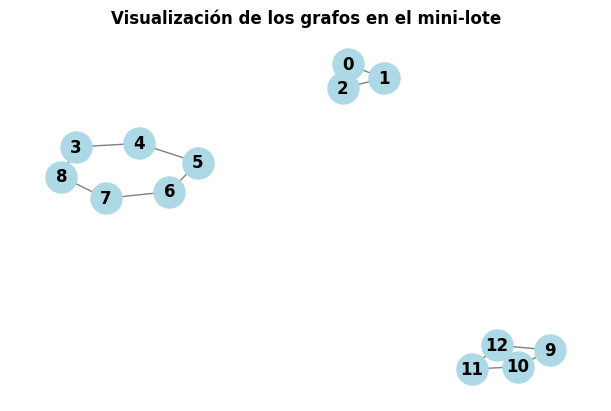

In [9]:
# Convertir el objeto de mini-lote de PyTorch Geometric a un grafo de NetworkX
# Se especifica 'to_undirected=True' porque los grafos de origen son no dirigidos
G_lote = to_networkx(lote, to_undirected=True)

# Crear la figura y el eje con Matplotlib para definir un lienzo claro de 6x4 pulgadas
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

# Calcular la disposición bidimensional de los nodos usando el algoritmo de fuerza 'spring'
# Fijamos una semilla (seed=42) para que el diseño sea reproducible en cada ejecución
pos = nx.spring_layout(G_lote, seed=42)

# Dibujar el grafo en el eje configurado utilizando estilos personalizados
nx.draw(
    G_lote,
    pos,
    ax=ax,
    with_labels=True,       # Mostrar las etiquetas (número) de cada nodo
    node_color="lightblue", # Color de fondo de los nodos
    edge_color="gray",      # Color de las aristas que conectan los nodos
    node_size=500,          # Tamaño visible de los nodos
    font_weight="bold"      # Texto en negrita para los números de los nodos
)

# Añadir un título formal a la visualización
ax.set_title("Visualización de los grafos en el mini-lote", fontsize=12, fontweight='bold')
plt.show()

## Previo 3. El grafo radial de un cristal

En un cristal, los nodos son los átomos y hay una arista entre dos átomos a menos de un radio de corte $r_c$, contando las **imágenes periódicas**: un átomo cerca del borde de la celda tiene vecinos en la celda de al lado. ASE lo resuelve con `neighbor_list`: `i, j, d = neighbor_list("ijd", atoms, rc)` devuelve una arista dirigida $i\to j$ por cada par de átomos a menos de `rc`, con su distancia `d`.

Usamos el silicio, con estructura de diamante y $a=5.431$ Å. Complete `vecinos_por_atomo`.

In [10]:
# Construcción de la celda unitaria de Silicio
# Se crea una estructura de silicio cristalino con geometría de diamante y constante de red experimental a = 5.431 Å
si = bulk("Si", "diamond", a=5.431)
print(si)

# Mostrar de manera enriquecida el número total de átomos en la celda primitiva (deben ser 2 átomos)
dMarkdown(f"**Atomos en la celda primitiva:** {len(si)}")

# Definición del cálculo de vecinos considerando condiciones periódicas de contorno
def vecinos_por_atomo(atoms, rc):
    """Número medio de vecinos por átomo a menos de rc (Å), con las imágenes periódicas."""
    # 'neighbor_list' con el modo "ijd" busca los índices i (átomo de origen), j (átomo de destino,
    # que puede ser una imagen periódica) y d (la distancia) que están a una distancia menor a 'rc'
    i, j, d = neighbor_list("ijd", atoms, rc)

    # El número total de aristas encontradas es 'len(i)'.
    # Dividimos por el número total de átomos en la celda primitiva para obtener el promedio de vecinos por átomo.
    return len(i)/len(atoms)

Atoms(symbols='Si2', pbc=True, cell=[[0.0, 2.7155, 2.7155], [2.7155, 0.0, 2.7155], [2.7155, 2.7155, 0.0]])


**Atomos en la celda primitiva:** 2

In [11]:
# Verificación del previo 3
assert vecinos_por_atomo(si, 3.0) == 4, "Cada Si tiene 4 primeros vecinos a 2,35 Å"
assert vecinos_por_atomo(si, 4.0) == 16, "Con 12 segundos vecinos a 3,84 Å suman 16"
print("Previo 3 correcto")

Previo 3 correcto


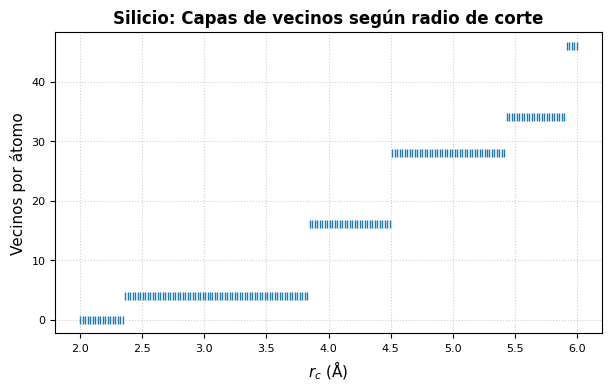

In [12]:
# Crear un arreglo de 200 puntos equiespaciados entre r_c = 2.0 Å y r_c = 6.0 Å
radios = np.linspace(2.0, 6.0, 200)

# Crear la figura y el eje usando el diseño ajustado 'constrained'
fig, ax = plt.subplots(figsize=(6, 3.8), layout='constrained')

# Graficar el número medio de vecinos para cada radio de corte
# Se calcula el número de vecinos periódicos por átomo evaluando la función definida anteriormente
ax.plot(
    radios,
    [vecinos_por_atomo(si, r) for r in radios],
    color='tab:blue',
    marker='|', # Usar barras verticales como marcador para resaltar las discontinuidades/capas
    ls='None',  # No conectar los puntos con líneas para denotar que son capas discretas
    lw=1,
    label='Vecinos'
)

# Personalización de los ejes, título y cuadrícula
ax.set_xlabel("$r_c$ (Å)", fontsize=11)
ax.set_ylabel("Vecinos por átomo", fontsize=11)
ax.set_title("Silicio: Capas de vecinos según radio de corte",
             fontsize=12, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

La celda primitiva tiene solo 2 átomos, pero con $r_c=4$ Å cada uno tiene 16 vecinos: casi todos son **imágenes periódicas**. Por eso el grafo de un cristal puede tener varias aristas entre los mismos dos átomos de la celda, una por cada imagen. En la parte A2 cada cristal será un grafo así, con $r_c=5$ Å.

## Previo 4. MACE-MP-0 como calculador de ASE

`mace_mp` carga el modelo fundacional MACE-MP-0 (la primera vez lo descarga) y lo devuelve como un **calculador** de ASE: cualquier estructura que lo tenga asignado entrega energía, fuerzas y esfuerzos. Usamos una supercelda de 64 átomos de silicio con los átomos desplazados al azar 0,05 Å; en el cristal perfecto todas las fuerzas serían cero por simetría.

In [13]:
# Crear una celda cúbica convencional de Silicio (8 átomos) y repetirla 2x2x2 para generar una supercelda de 64 átomos
si64 = bulk("Si", "diamond", a=5.431, cubic=True).repeat((2, 2, 2))

# Desplazar ligeramente los átomos al azar (rattle) con una desviación estándar de 0.05 Å para romper la simetría perfecta
si64.rattle(stdev=0.05, seed=0)

# Asignar el calculador neuronal MACE-MP-0 a la estructura de silicio
si64.calc = calc

# Calcular las propiedades físicas del sistema utilizando el potencial interatómico
E = si64.get_potential_energy()  # Energía potencial total en eV
F = si64.get_forces()            # Vector de fuerzas sobre cada átomo (eV/Å)
S = si64.get_stress()            # Tensor de esfuerzos en notación de Voigt (eV/Å³)

# Mostrar los resultados formateados en Markdown con el esfuerzo convertido a Gigapascales (GPa)
dMarkdown(f"""
### Resultados de la Simulación del Silicio:
* **Energía Total ($E$):** {E:.4f} eV
* **Energía por Átomo:** {E/len(si64):.4f} eV/átomo
* **Fuerza Máxima:** {np.abs(F).max():.3f} eV/Å
* **Esfuerzo (GPa, notación de Voigt):** {np.round(S/GPa, 3).tolist()}
""")


### Resultados de la Simulación del Silicio:
* **Energía Total ($E$):** -339.9497 eV
* **Energía por Átomo:** -5.3117 eV/átomo
* **Fuerza Máxima:** 1.439 eV/Å
* **Esfuerzo (GPa, notación de Voigt):** [-1.68, -1.655, -1.727, -0.042, -0.524, 0.444]



**Observe:** las tres primeras componentes del esfuerzo, la diagonal, no son cero; son negativas y casi iguales.  

**Pista:** usamos la constante de red experimental, $a=5.431$ Å, y MACE-MP-0 aprendió de cálculos con el funcional PBE.

El funcional **PBE** con el que fue entrenado MACE-MP-0 tiende a subestimar ligeramente la rigidez de los enlaces y **sobreestima la constante de red de equilibrio** del silicio ($a_{\text{PBE}} \approx 5.47\,\text{Å}$) respecto al valor experimental usado en la celda ($a = 5.431\,\text{Å}$). Por ello, para MACE-MP-0 el cristal está **comprimido** y tiende a expandirse para minimizar su energía.

En la convención de ASE:
$$\sigma_{\alpha\beta} = \frac{1}{V}\frac{\partial E}{\partial \varepsilon_{\alpha\beta}},$$
esta compresión produce **esfuerzos diagonales negativos** equivale a una presión hidrostática positiva de $\approx 1.69\,\text{GPa}$.

Las tres componentes son casi iguales porque la compresión de una red cúbica es isotrópica; las pequeñas diferencias entre ellas provienen de la aleatorización introducida por `rattle`.

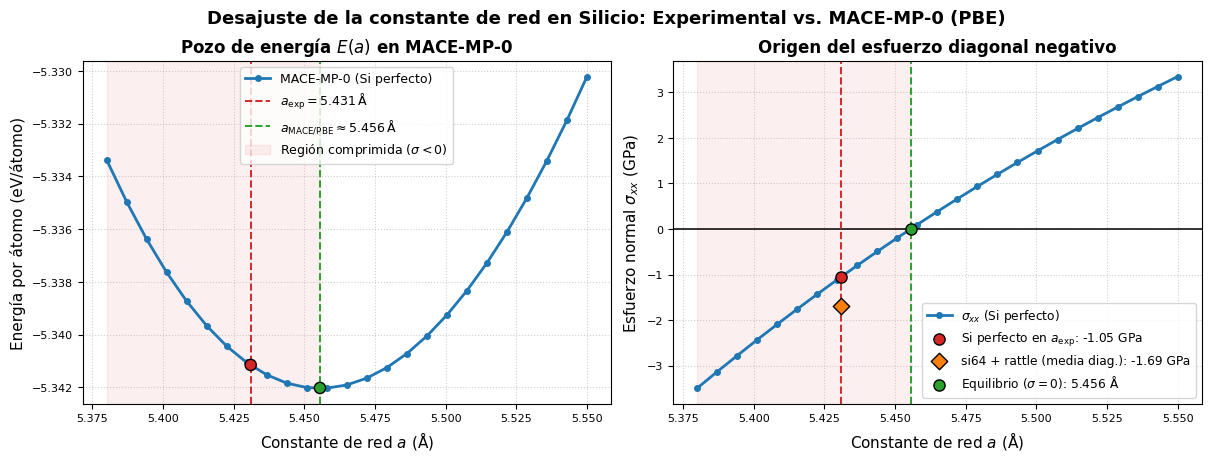

In [14]:
# Barrido de la constante de red a alrededor del valor experimental (5.431 Å) y el de PBE (~5.47 Å)
a_vals = np.linspace(5.38, 5.55, 25)
energias_atomo = []
esfuerzo_diag = []

for a in a_vals:
    si_test = bulk("Si", "diamond", a=a)
    si_test.calc = calc
    energias_atomo.append(si_test.get_potential_energy() / len(si_test))
    # En un cristal cúbico perfecto, S_xx = S_yy = S_zz
    esfuerzo_diag.append(si_test.get_stress()[0] / GPa)

energias_atomo = np.array(energias_atomo)
esfuerzo_diag = np.array(esfuerzo_diag)

# Constante de red de equilibrio de MACE-MP-0 (donde el esfuerzo cruza 0 GPa)
a_eq = np.interp(0.0, esfuerzo_diag, a_vals)
E_eq = np.interp(a_eq, a_vals, energias_atomo)

# Valores en la constante de red experimental (cristal perfecto vs. supercelda con rattle)
a_exp = 5.431
E_exp = np.interp(a_exp, a_vals, energias_atomo)
S_exp_perf = np.interp(a_exp, a_vals, esfuerzo_diag)
S_exp_rattle = np.mean(S[:3]) / GPa  # promedio diagonal de si64 del Previo 4

# --- Figura de dos paneles ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")

# Panel 1: Energía por átomo vs. constante de red
ax1.plot(a_vals, energias_atomo, "o-", color="tab:blue", lw=2, ms=4, label="MACE-MP-0 (Si perfecto)")
ax1.axvline(a_exp, color="tab:red", ls="--", lw=1.4, label=f"$a_{{\\mathrm{{exp}}}} = {a_exp}\\,$Å")
ax1.axvline(a_eq, color="tab:green", ls="--", lw=1.4, label=f"$a_{{\\mathrm{{MACE/PBE}}}} \\approx {a_eq:.3f}\\,$Å")
ax1.scatter([a_exp, a_eq], [E_exp, E_eq], color=["tab:red", "tab:green"], edgecolor="black", s=65, zorder=5)
ax1.axvspan(a_vals.min(), a_eq, color="tab:red", alpha=0.07, label="Región comprimida ($\\sigma < 0$)")
ax1.set_xlabel("Constante de red $a$ (Å)", fontsize=11)
ax1.set_ylabel("Energía por átomo (eV/átomo)", fontsize=11)
ax1.set_title("Pozo de energía $E(a)$ en MACE-MP-0", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=9, frameon=True)

# Panel 2: Esfuerzo diagonal vs. constante de red
ax2.plot(a_vals, esfuerzo_diag, "o-", color="tab:blue", lw=2, ms=4, label="$\\sigma_{xx}$ (Si perfecto)")
ax2.axhline(0, color="black", lw=1.1)
ax2.axvline(a_exp, color="tab:red", ls="--", lw=1.4)
ax2.axvline(a_eq, color="tab:green", ls="--", lw=1.4)
ax2.scatter([a_exp], [S_exp_perf], color="tab:red", edgecolor="black", s=65, zorder=5,
            label=f"Si perfecto en $a_{{\\mathrm{{exp}}}}$: {S_exp_perf:.2f} GPa")
ax2.scatter([a_exp], [S_exp_rattle], color="tab:orange", marker="D", edgecolor="black", s=70, zorder=6,
            label=f"si64 + rattle (media diag.): {S_exp_rattle:.2f} GPa")
ax2.scatter([a_eq], [0.0], color="tab:green", edgecolor="black", s=65, zorder=5,
            label=f"Equilibrio ($\\sigma = 0$): {a_eq:.3f} Å")
ax2.axvspan(a_vals.min(), a_eq, color="tab:red", alpha=0.07)
ax2.set_xlabel("Constante de red $a$ (Å)", fontsize=11)
ax2.set_ylabel("Esfuerzo normal $\\sigma_{xx}$ (GPa)", fontsize=11)
ax2.set_title("Origen del esfuerzo diagonal negativo", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=8.8, frameon=True, loc="lower right")

fig.suptitle("Desajuste de la constante de red en Silicio: Experimental vs. MACE-MP-0 (PBE)",
             fontsize=13, fontweight="bold")
plt.show()

El barrido de la constante de red confirma dos contribuciones al esfuerzo diagonal negativo ($\bar{\sigma}_{\text{diag}} = -1.69\,\text{GPa}$):

1. **Sesgo del funcional PBE ($\approx -1.05\,\text{GPa}$, ~62% del efecto):** el mínimo de energía de MACE-MP-0 para el silicio perfecto se encuentra en $a_{\text{MACE/PBE}} \approx 5.456\,\text{Å}$ ($\sigma = 0$). Al usar la constante experimental $a_{\text{exp}} = 5.431\,\text{Å} < a_{\text{MACE/PBE}}$, la celda queda comprimida sobre la pared izquierda del pozo de energía.
2. **Anharmonicidad por el desplazamiento `rattle` ($\approx -0.64\,\text{GPa}$, ~38% del efecto):** al desplazar los átomos al azar $0.05\,\text{Å}$ a volumen fijo, los enlaces que se acortan encuentran una barrera repulsiva más empinada que la atracción de los enlaces que se estiran, añadiendo una presión interna compresiva extra (análoga a la presión térmica) y rompiendo ligeramente la igualdad entre $\sigma_{xx}, \sigma_{yy}$ y $\sigma_{zz}$.

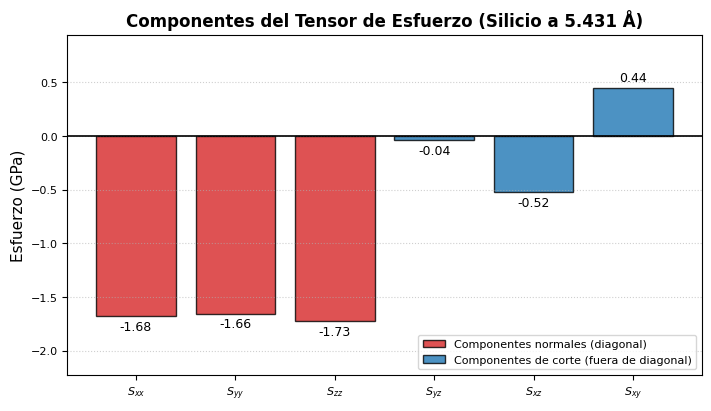

In [15]:
# Etiquetas para las 6 componentes del esfuerzo en notación de Voigt
etiquetas = ['$S_{xx}$', '$S_{yy}$', '$S_{zz}$', '$S_{yz}$', '$S_{xz}$', '$S_{xy}$']

# Convertir el esfuerzo a GPa usando las variables del entorno
esfuerzos_gpa = S / GPa

# Crear la figura
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')

# Colores: rojo para las normales (diagonal), azul para las de corte
colores = ['tab:red' if i < 3 else 'tab:blue' for i in range(6)]

# Crear el gráfico de barras
barras = ax.bar(etiquetas, esfuerzos_gpa, color=colores, edgecolor='black', alpha=0.8)

# Línea horizontal en 0 para referencia
ax.axhline(0, color='black', linewidth=1.2)

# Configuración estética
ax.set_ylabel("Esfuerzo (GPa)", fontsize=11)
ax.set_title("Componentes del Tensor de Esfuerzo (Silicio a 5.431 Å)", fontsize=12, fontweight='bold')
ax.grid(axis='y', linestyle=':', alpha=0.6)

# Añadir los valores sobre/bajo las barras para más claridad
ax.bar_label(barras, fmt='%.2f', padding=3, fontsize=9)

# Ajustar el límite inferior para que los números no se corten
ax.set_ylim(min(esfuerzos_gpa) - 0.5, max(max(esfuerzos_gpa) + 0.5, 0.5))

# Añadir leyenda manual para los colores
from matplotlib.patches import Patch
leyenda_elementos = [
    Patch(facecolor='tab:red', edgecolor='black', alpha=0.8, label='Componentes normales (diagonal)'),
    Patch(facecolor='tab:blue', edgecolor='black', alpha=0.8, label='Componentes de corte (fuera de diagonal)')
]
ax.legend(handles=leyenda_elementos, loc='lower right', frameon=True)

plt.show()

**Banco de simetrías.** La energía debe ser **invariante** y las fuerzas **equivariantes**: al rotar la estructura con $R$, $\mathbf F_i\to R\,\mathbf F_i$; al trasladarla, nada cambia; al permutar los átomos, las fuerzas se permutan con ellos. Complete `banco_de_simetrias`, que devuelve los errores de cada prueba. La función `rotacion` y la forma de rotar una celda periódica ya están escritas: se rotan juntas la celda y las posiciones.

In [16]:
def rotacion(eje, angulo):
    """Matriz de rotación de `angulo` grados alrededor de `eje` (fórmula de Rodrigues)."""
    # Normalizar el vector del eje de rotación
    u = np.asarray(eje, dtype=float)/np.linalg.norm(eje)
    # Convertir el ángulo a radianes
    a = np.radians(angulo)
    # Matriz antisimétrica para el producto vectorial
    K = np.array([[0, -u[2], u[1]], [u[2], 0, -u[0]], [-u[1], u[0], 0]])
    # Fórmula de rotación de Rodrigues en 3D
    return np.eye(3) + np.sin(a)*K + (1 - np.cos(a))*K@K

def evaluar(atoms, calc):
    """Calcula de forma aislada la energía potencial y las fuerzas de una estructura."""
    a = atoms.copy()
    a.calc = calc
    return a.get_potential_energy(), a.get_forces()

def rotar(atoms, R):
    """Aplica la matriz de rotación R tanto a la celda como a las posiciones de los átomos."""
    a = atoms.copy()
    # Rotar vectores de la celda unitaria
    a.set_cell(atoms.cell[:]@R.T, scale_atoms=False)
    # Rotar las posiciones de todos los átomos
    a.positions = atoms.positions@R.T
    return a

def banco_de_simetrias(atoms, calc, R, t, perm):
    """Calcula los errores de energía (E) y fuerzas (F) al aplicar simetrías del espacio real.

    Parámetros:
    atoms: Estructura original de ASE.
    calc: Calculador (MACE) a evaluar.
    R: Matriz de rotación 3x3.
    t: Vector de traslación 3D.
    perm: Vector de permutación de índices de los átomos.
    """
    # Evaluar la estructura en el estado original de referencia
    E0, F0 = evaluar(atoms, calc)

    # Prueba de Rotación: la energía debe ser idéntica y las fuerzas rotar solidariamente con el sistema
    E1, F1 = evaluar(rotar(atoms, R), calc)

    # Prueba de Traslación: la energía y fuerzas deben ser invariantes ante traslaciones homogéneas
    trasladada = atoms.copy()
    trasladada.positions = atoms.positions + t
    E2, F2 = evaluar(trasladada, calc)

    # Prueba de Permutación: la energía debe ser igual y las fuerzas se deben reordenar según la permutación
    E3, F3 = evaluar(atoms[perm], calc)

    # Devolver diccionario con las diferencias absolutas para cada caso (deberían ser cercanas a cero)
    return {
        "rotación: \\|E' - E\\| (eV)": abs(E1 - E0),
        "rotación: máx \\|F' - R F\\| (eV/Å)": np.abs(F1 - F0@R.T).max(),
        "traslación: \\|E' - E\\| (eV)": abs(E2 - E0),
        "traslación: máx \\|F' - F\\| (eV/Å)": np.abs(F2 - F0).max(),
        "permutación: \\|E' - E\\| (eV)": abs(E3 - E0),
        "permutación: máx \\|F' - F[perm]\\| (eV/Å)": np.abs(F3 - F0[perm]).max()
    }

In [17]:
# Definir los parámetros de simetría del espacio real para la prueba
# Generar una matriz de rotación de 37 grados respecto al eje oblicuo [1, 2, 3]
R = rotacion([1, 2, 3], 37)
# Definir un vector de traslación tridimensional arbitrario
t = np.array([0.3, -1.1, 2.0])
# Crear una permutación aleatoria de los índices de los 64 átomos del silicio
perm = np.random.default_rng(0).permutation(len(si64))

# Evaluar la invarianza/equivarianza en el potencial interatómico MACE-MP-0
errores = banco_de_simetrias(si64, calc, R, t, perm)

# Preparar los datos resultantes de las discrepancias para mostrarlos en una tabla
filas_tabla = [[prueba, f"{error:.1e}"]
               for prueba, error in errores.items()]
dM_table(filas_tabla,
         headers=["Prueba de Simetría",
                  "Error Evaluado"])

# Asegurar que las discrepancias sean numéricamente despreciables (tolerancia física de 1e-6)
assert max(errores.values()) < 1e-6, "Algún error es demasiado grande: revise la prueba correspondiente"
print("Previo 4 correcto")

| Prueba de Simetría                       |   Error Evaluado |
|:-----------------------------------------|-----------------:|
| rotación: \|E' - E\| (eV)                |          0       |
| rotación: máx \|F' - R F\| (eV/Å)        |          1.8e-14 |
| traslación: \|E' - E\| (eV)              |          0       |
| traslación: máx \|F' - F\| (eV/Å)        |          1.2e-14 |
| permutación: \|E' - E\| (eV)             |          0       |
| permutación: máx \|F' - F[perm]\| (eV/Å) |          1.1e-15 |

Previo 4 correcto


# Parte A1 - Nodos en el coloide: una GCN frente a la regresión logística

Volvemos al coloide del Lab 14: un instante con unas 4700 partículas, el grafo de vecinos a menos de $r_c=1.41\,d$ y la etiqueta experimental "cristalina" ($N_o\ge8$). En el Lab 14, la regresión logística con rasgos hechos a mano, incluidas las agregaciones $h^{(1)}=A\mathbf d$ y $h^{(2)}=A\,h^{(1)}$, llegó a una exactitud de 0,89 en toda la muestra y 0,68 en la franja de la interfaz.

Ahora la red aprende la agregación: le damos solo dos rasgos **locales**, el grado y el coeficiente de agrupamiento, y dos capas GCN. La celda siguiente carga los datos y prepara todo.

In [18]:
# Descargar y extraer los datos experimentales del sistema coloidal si no están presentes de forma local
if not Path("hp02s5bb.txt").exists():
    if not Path("pnas09.zip").exists():
        urlretrieve("https://faculty.college.emory.edu/sites/weeks/data/pnas09.zip", "pnas09.zip")
    ZipFile("pnas09.zip").extractall()

# Cargar el conjunto de datos y filtrar las posiciones y etiquetas para el instante inicial t = 0
datos = np.loadtxt("hp02s5bb.txt")
f0 = datos[datos[:, 5] == 0]   # Filtrar por instante temporal t = 0
X, N_o = f0[:, :3], f0[:, 3]   # X: Coordenadas 3D de las partículas; N_o: Número de enlaces ordenados
y_nodo = (N_o > 7).astype(int) # Clasificación binaria (1 si es cristalino, 0 si es líquido)
n = len(X)                     # Número total de partículas (nodos)
rc = 1.41*2.30                 # Radio de corte óptimo para definir los vecinos geométricos

# Construir la estructura de grafo basada en las distancias interpartículas
pares = np.array(sorted(cKDTree(X).query_pairs(rc))) # Encontrar todos los pares de partículas que están a menos del radio de corte
G = nx.Graph()
G.add_nodes_from(range(n))
G.add_edges_from(map(tuple, pares))

# Calcular rasgos estructurales locales y agregados (paso de mensajes hecho a mano)
A = nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr", dtype=float)
grado = np.asarray(A.sum(axis=1)).ravel() # Grado local de cada nodo (número de primeros vecinos)
agrup = nx.clustering(G)
agrupamiento = np.array([agrup[u] for u in range(n)]) # Coeficiente de agrupamiento local
h1 = A@grado # Primera agregación espacial de grado por la matriz de adyacencia
h2 = A@h1    # Segunda agregación espacial
agrup_vecinos = (A@agrupamiento)/np.maximum(grado, 1) # Coeficiente de agrupamiento medio de los vecinos directos

# Agrupar los rasgos para el modelo clásico del Laboratorio 14 frente al enfoque GCN local
rasgos_lab14 = np.column_stack([grado, agrupamiento, h1, h2, agrup_vecinos])
rasgos_locales = np.column_stack([grado, agrupamiento]) # Rasgos minimalistas de partida para la GCN

# Escalar los atributos de entrada y empaquetar el sistema en un objeto Data de PyTorch Geometric (PyG)
x = StandardScaler().fit_transform(rasgos_locales)
edge_index = to_undirected(torch.tensor(pares.T, dtype=torch.long), num_nodes=n)
coloide = Data(x=torch.tensor(x, dtype=torch.float), edge_index=edge_index,
               y=torch.tensor(y_nodo, dtype=torch.long))

# Definir la franja espacial representativa de la interfaz sólido-líquido
franja = (X[:, 0] > 27) & (X[:, 0] < 36)

# Mostrar el resumen del grafo y la proporción de orden de largo alcance
print(coloide)
dMarkdown(f"**Fracción cristalina:** {y_nodo.mean():.3f}")

Data(x=[4691, 2], edge_index=[2, 45926], y=[4691])


**Fracción cristalina:** 0.562

## Tarea A1. La GCN
Complete la clase `GCN`: una capa `GCNConv(entradas, ocultas)`, ReLU, *dropout* con $p=0.5$ y una segunda capa `GCNConv(ocultas, 2)` que da un puntaje por clase. Recuerde de la sesión 3 que `GCNConv` ya añade los auto-lazos y la normalización simétrica $\hat A$.

In [19]:
class GCN(torch.nn.Module):
    def __init__(self, entradas, ocultas=32, clases=2):
        super().__init__()
        # Primera capa de convolución de grafos (GCNConv):
        # Proyecta las características de entrada al espacio oculto y agrega información de los vecinos directos
        self.conv1 = GCNConv(entradas, ocultas)
        # Segunda capa de convolución de grafos:
        # Proyecta las características del espacio oculto al número de clases para clasificación binaria
        self.conv2 = GCNConv(ocultas, clases)

    def forward(self, x, edge_index):
        # Aplicar la primera convolución de grafos usando las características y conectividad
        x = self.conv1(x, edge_index)
        # Aplicar la función de activación no lineal ReLU
        x = fn.relu(x)
        # Aplicar dropout del 50% durante el entrenamiento para evitar el sobreajuste
        x = fn.dropout(x, p=0.5, training=self.training)
        # Pasar por la segunda capa de convolución para obtener los logits finales de predicción
        x = self.conv2(x, edge_index)
        return x

In [20]:
# Verificación de la tarea A1
salida = GCN(2)(coloide.x, coloide.edge_index)
assert salida.shape == (n, 2), f"La salida debe tener forma ({n}, 2), no {tuple(salida.shape)}"
print("Tarea A1 correcta")

Tarea A1 correcta


In [21]:
# Instanciar el modelo GCN con 2 características de entrada
modelo_gcn = GCN(2)

# Calcular la cantidad de parámetros entrenables
parametros = sum(p.numel() for p in modelo_gcn.parameters() if p.requires_grad)

# Mostrar la arquitectura y parámetros usando dMarkdown para una mejor visualización
dMarkdown(f"""
### Arquitectura del modelo GCN:
```text
{modelo_gcn}
```

**Total de parámetros entrenables:** {parametros}
""")


### Arquitectura del modelo GCN:
```text
GCN(
  (conv1): GCNConv(2, 32)
  (conv2): GCNConv(32, 2)
)
```

**Total de parámetros entrenables:** 162


La celda siguiente entrena la GCN con el 30 % de las partículas etiquetadas, la misma separación del Lab 14, y la compara con dos regresiones logísticas: con los dos rasgos locales y con los cinco rasgos del Lab 14. Repite con 5 semillas; tarda menos de un minuto en GPU.

In [22]:
def entrenar_gcn(semilla, epocas=200):
    # Fijar la semilla de PyTorch para garantizar la reproducibilidad
    torch.manual_seed(semilla)
    # Separar aleatoriamente 30% para entrenamiento y 70% para prueba de forma estratificada
    tr, te = train_test_split(
        np.arange(n),
        train_size=0.3,
        random_state=semilla,
        stratify=y_nodo
        )
    # Instanciar el modelo GCN y transferirlo al dispositivo (GPU o CPU)
    modelo = GCN(2).to(dispositivo)
    datos_gpu = coloide.to(dispositivo)
    tr_t = torch.tensor(tr, device=dispositivo)
    # Optimizador Adam con tasa de aprendizaje de 0.01 y decaimiento de pesos L2
    optimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=0.01,
        weight_decay=5e-4
        )
    # Bucle principal de entrenamiento del modelo
    for _ in range(epocas):
        modelo.train()
        optimizador.zero_grad()
        # Calcular la pérdida de entropía cruzada utilizando solo los nodos del subconjunto de entrenamiento
        perdida = fn.cross_entropy(
            modelo(datos_gpu.x,
                   datos_gpu.edge_index
                   )[tr_t], datos_gpu.y[tr_t])
        perdida.backward()
        optimizador.step()
    # Evaluación del modelo entrenado
    modelo.eval()
    with torch.no_grad():
        # Obtener las predicciones tomando la clase con la probabilidad más alta
        prediccion = modelo(
            datos_gpu.x,
            datos_gpu.edge_index
            ).argmax(dim=1).cpu().numpy()
    return prediccion, te

def exactitudes(prediccion, te):
    # Evaluar las predicciones en toda la muestra de prueba y específicamente en la franja de la interfaz
    te_f = te[franja[te]]
    return np.mean(prediccion[te] == y_nodo[te]), \
           np.mean(prediccion[te_f] == y_nodo[te_f])

# Diccionario para almacenar las métricas de cada modelo y enfoque experimental
resultados = {"regresión logística, 2 rasgos locales": [],
              "regresión logística, 5 rasgos del Lab 14": [],
              "GCN, 2 rasgos locales": []}

# Bucle experimental que itera sobre 5 semillas aleatorias distintas
for semilla in range(5):
    tr, te = train_test_split(np.arange(n), train_size=0.3, random_state=semilla, stratify=y_nodo)
    # Evaluar los modelos baselines de regresión logística clásicos
    for nombre, M in [("regresión logística, 2 rasgos locales",
                       rasgos_locales),
                      ("regresión logística, 5 rasgos del Lab 14",
                       rasgos_lab14)]:
        logistica = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000)
            ).fit(M[tr], y_nodo[tr])
        resultados[nombre].append(exactitudes(logistica.predict(M), te))
    # Entrenar la red neuronal convolucional de grafos (GCN)
    prediccion_gcn, te_gcn = entrenar_gcn(semilla)
    resultados["GCN, 2 rasgos locales"].append(
        exactitudes(prediccion_gcn, te_gcn))

# Construir y presentar la tabla comparativa final promediando los resultados de todas las semillas
filas_tabla = []
for nombre, valores in resultados.items():
    total, interfaz = np.mean(valores, axis=0)
    filas_tabla.append([nombre, f"{total:.3f}", f"{interfaz:.3f}"])

dM_table(filas_tabla,
         headers=["Modelo",
                  "Toda la muestra (Exactitud)",
                  "Interfaz (Exactitud)"]
         )

| Modelo                                   |   Toda la muestra (Exactitud) |   Interfaz (Exactitud) |
|:-----------------------------------------|------------------------------:|-----------------------:|
| regresión logística, 2 rasgos locales    |                         0.811 |                  0.604 |
| regresión logística, 5 rasgos del Lab 14 |                         0.891 |                  0.679 |
| GCN, 2 rasgos locales                    |                         0.903 |                  0.678 |

Los aciertos y errores de la GCN (última semilla) en una lámina de la muestra ($8<z<10$ µm): en azul las partículas cristalinas según los autores, con borde rojo las mal clasificadas.

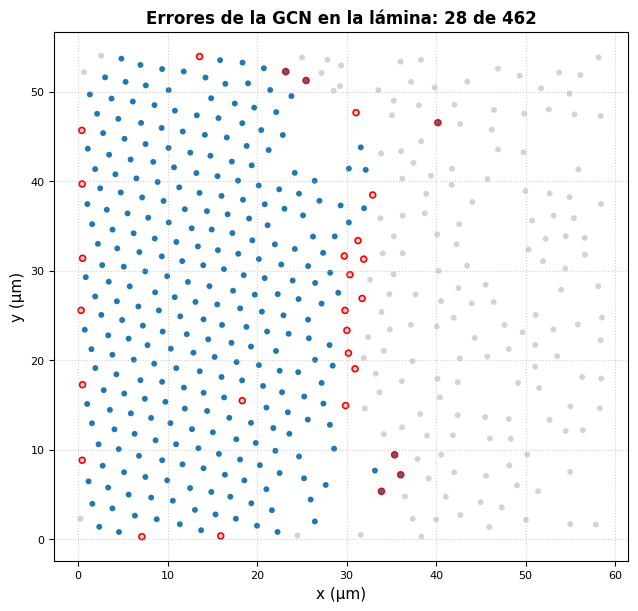

In [23]:
# Filtrar una porción o lámina en el eje Z (entre 8 y 10 micrómetros) para simplificar la visualización 2D
lamina = (X[:, 2] > 8) & (X[:, 2] < 10)

# Determinar los índices donde las predicciones de la GCN difieren de las etiquetas reales de los autores
error = prediccion_gcn != y_nodo

# Configurar la figura y el lienzo usando un diseño ajustado autocontenido
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')

# Graficar las partículas de la lámina proyectadas en el plano X-Y
ax.scatter(
    *X[lamina, :2].T,
    s=18,
    # Pintar de azul las partículas realmente cristalinas y de gris claro las líquidas
    c=np.where(y_nodo[lamina] == 1, "tab:blue", "lightgray"),
    # Resaltar con borde rojo los nodos que la red GCN clasificó de forma incorrecta
    edgecolors=np.where(error[lamina], "red", "none"),
    linewidths=1.2
)

# Configuración estética de las etiquetas de los ejes y relación de aspecto proporcional
ax.set_xlabel("x (µm)", fontsize=11)
ax.set_ylabel("y (µm)", fontsize=11)
ax.set_aspect("equal")

# Título descriptivo indicando el volumen de errores detectados en la sección analizada
ax.set_title(f"Errores de la GCN en la lámina: {error[lamina].sum()} de {lamina.sum()}", fontsize=12, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Discutan:**

* **Con solo dos rasgos locales, ¿alcanza la GCN a la regresión logística con las agregaciones hechas a mano?**

Sí, la alcanza e incluso la supera ligeramente en la muestra completa.Mientras que la regresión logística con los 5 rasgos (incluyendo las agregaciones manuales $h^{(1)}$, $h^{(2)}$ y el agrupamiento medio de vecinos) obtuvo una exactitud de $0.891$ global y $0.679$ en la interfaz, la GCN, partiendo únicamente de los 2 rasgos locales, alcanzó $0.903$ en toda la muestra y $0.678$ en la interfaz, superando ampliamente el $0.811$ global y $0.604$ en interfaz de la regresión logística entrenada con esos mismos 2 rasgos.

* **¿Qué hacen las dos capas GCN que hacían a mano $h^{(1)}$ y $h^{(2)}$?**

Las capas GCN realizan la agregación de información (paso de mensajes) de los vecinos de forma automática.
  * La primera capa GCN recoge la información de los vecinos directos (análogo a $h^{(1)}$).
  * La segunda capa recoge información de los vecinos de los vecinos (análogo a $h^{(2)}$).

La diferencia es que la GCN aprende los pesos óptimos para combinar estas características durante el entrenamiento, en lugar de ser una simple multiplicación de matrices predefinida.

* **¿Por qué la exactitud en la interfaz sigue siendo baja?**

La interfaz es una región de transición donde las partículas tienen vecindarios mixtos: parcialmente agrupados y parcialmente desagrupados, lo que hace que sus descriptores locales sean ambiguos y la clasificación falla.

* **Piense en qué información usa la etiqueta $N_o$ (direcciones de los enlaces) y cuál ve la GCN.**

El parámetro de orden de Steinhardt ($N_o$) que usan los autores para etiquetar los datos depende fuertemente de la **dirección y los ángulos** entre los vecinos en el espacio 3D. Esta GCN sencilla solo tiene en cuenta la topología del grafo: el grado y el agrupamiento (quién está conectado con quién), ignorando la geometría espacial y angular de los enlaces.

* **En la figura, ¿hay errores lejos de la interfaz? ¿Dónde están y por qué?**

A diferencia del notebook 14, se observan además otros tipos de errores fuera de la interfaz en las fronteras y defectos puntuales que alteran la topología local del grafo, haciendo que parezca menos ordenado.<br>
 * En la fase "líquida", pueden deberse a fluctuaciones térmicas que crean pequeños clústeres transitorios con un orden local alto (potenciales puntos de nucleación si las condiciones cambian), pero siguen siendo falsos positivos o negativos para la red topológica.
* En la fase "sólida", los bordes también funcionan como fronteras físicas que no se tienen en cuenta en el entrenamiento de la red de grafos

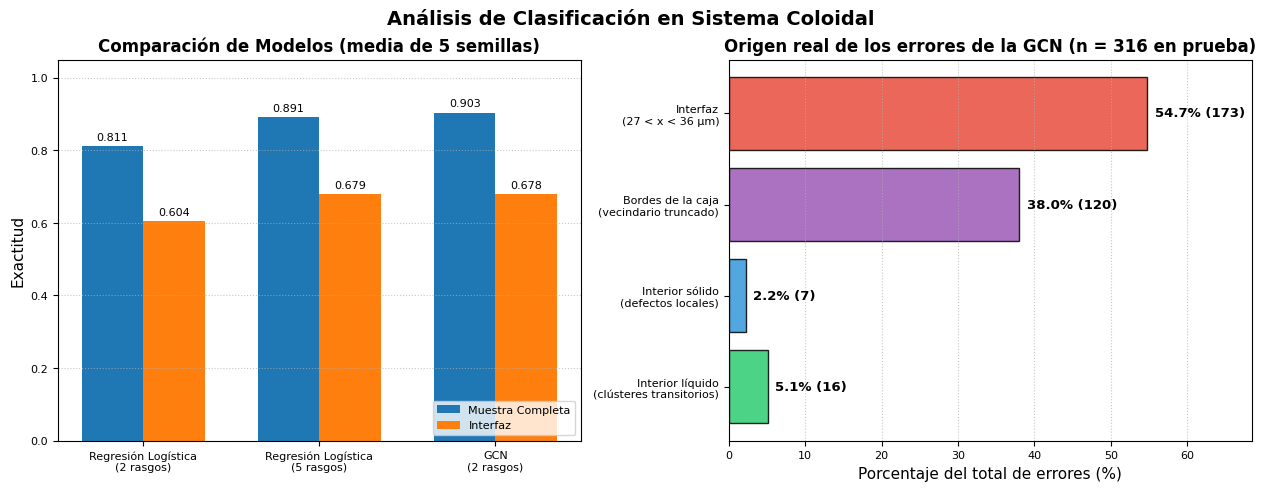

In [24]:
# Extraer las exactitudes reales promediadas sobre las 5 semillas
modelos = ['Regresión Logística\n(2 rasgos)', 'Regresión Logística\n(5 rasgos)', 'GCN\n(2 rasgos)']
exactitud_global = []
exactitud_interfaz = []

for nombre, valores in resultados.items():
    total, interfaz = np.mean(valores, axis=0)
    exactitud_global.append(total)
    exactitud_interfaz.append(interfaz)

# --- Desglose REAL de los errores de la GCN en el conjunto de prueba (te_gcn) ---
err_te = (prediccion_gcn[te_gcn] != y_nodo[te_gcn])
X_err = X[te_gcn][err_te]
y_err = y_nodo[te_gcn][err_te]

# Máscaras mutuamente excluyentes
en_interfaz = (X_err[:, 0] > 27) & (X_err[:, 0] < 36)

# Partículas a menos de rc de cualquier frontera de la caja (grafo truncado)
mins, maxs = X.min(axis=0), X.max(axis=0)
en_borde = np.any((X_err - mins < rc) | (maxs - X_err < rc), axis=1) & (~en_interfaz)

en_solido = (~en_interfaz) & (~en_borde) & (X_err[:, 0] <= 27)
en_liquido = (~en_interfaz) & (~en_borde) & (X_err[:, 0] >= 36)

categorias_error = [
    'Interfaz\n(27 < x < 36 µm)',
    'Bordes de la caja\n(vecindario truncado)',
    'Interior sólido\n(defectos locales)',
    'Interior líquido\n(clústeres transitorios)'
]
conteos = [en_interfaz.sum(), en_borde.sum(), en_solido.sum(), en_liquido.sum()]
porcentajes = 100 * np.array(conteos) / len(X_err)

# --- Figura de dos paneles ---
x = np.arange(len(modelos))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), layout='constrained')

# Panel 1: Comparación de modelos
rects1 = ax1.bar(x - width/2, exactitud_global, width, label='Muestra Completa', color='tab:blue')
rects2 = ax1.bar(x + width/2, exactitud_interfaz, width, label='Interfaz', color='tab:orange')
ax1.set_ylabel('Exactitud', fontsize=11)
ax1.set_title('Comparación de Modelos (media de 5 semillas)', fontweight='bold', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(modelos)
ax1.legend(loc='lower right')
ax1.set_ylim(0, 1.05)
ax1.grid(axis='y', linestyle=':', alpha=0.7)
ax1.bar_label(rects1, padding=3, fmt='%.3f')
ax1.bar_label(rects2, padding=3, fmt='%.3f')

# Panel 2: Distribución REAL de los errores (barras horizontales con conteo y %)
colores_err = ['#e74c3c', '#9b59b6', '#3498db', '#2ecc71']
barras = ax2.barh(categorias_error[::-1], porcentajes[::-1], color=colores_err[::-1], edgecolor='black', alpha=0.85)
ax2.set_xlabel('Porcentaje del total de errores (%)', fontsize=11)
ax2.set_title(f'Origen real de los errores de la GCN (n = {len(X_err)} en prueba)', fontweight='bold', fontsize=12)
ax2.set_xlim(0, max(porcentajes) * 1.25)
ax2.grid(axis='x', linestyle=':', alpha=0.7)

for barra, c, p in zip(barras, conteos[::-1], porcentajes[::-1]):
    ax2.text(barra.get_width() + 1.0, barra.get_y() + barra.get_height()/2,
             f'{p:.1f}% ({c})', va='center', fontsize=9.5, fontweight='bold')

fig.suptitle('Análisis de Clasificación en Sistema Coloidal', fontsize=14, fontweight='bold')
plt.show()

# Parte A2 - Grafos de cristales: el módulo de compresibilidad

Usamos `matbench_log_kvrh` (Dunn et al., 2020): 10 987 cristales de Materials Project con el logaritmo de su **módulo de compresibilidad**, $\log_{10}K_{\mathrm{VRH}}$ (GPa), calculado con DFT a partir del tensor elástico (de Jong et al., 2015). $K_{\mathrm{VRH}}$ es el promedio de Voigt, Reuss y Hill: una medida de cuánto se resiste el cristal a una compresión uniforme.

Para que el entrenamiento quepa en la sesión tomamos 4000 cristales al azar con a lo sumo 30 átomos en la celda. El archivo pesa unos 4 MB. Si la descarga directa falla, use la alternativa con `matminer` que aparece justo después de las celdas de carga.

In [25]:
# URL del conjunto de datos matbench_log_kvrh de Materials Project con el módulo de compresibilidad
URL = "https://ml.materialsproject.org/projects/matbench_log_kvrh.json.gz"
archivo = Path("matbench_log_kvrh.json.gz")

# Descargar el archivo comprimido si no existe localmente en el entorno de ejecución
if not archivo.exists():
    # Usamos requests.get con tiempo límite de espera para evitar bloqueos HTTP 403 comunes con urlretrieve
    respuesta = requests.get(URL, timeout=300)
    respuesta.raise_for_status()
    # Escribir la respuesta binaria directamente al disco
    archivo.write_bytes(respuesta.content)

# Descomprimir y leer el archivo .gz de forma secuencial en modo texto para ahorrar memoria RAM
with gzip.open(archivo, "rt") as f:
    crudo = json.load(f)

# Recuperar los nombres de las columnas y el arreglo bidimensional de datos
columnas = crudo["columns"]
filas = crudo["data"]

# Identificar dinámicamente el índice posicional de la estructura cristalina y el módulo de compresibilidad objetivo
i_estructura, i_objetivo = columnas.index("structure"), columnas.index("log10(K_VRH)")

# Mostrar estadísticas del conjunto de datos cargado mediante Markdown
dMarkdown(f"""{len(filas)} cristales<br>
**Columnas:** {columnas}
""")

# Desplegar las claves generales contenidas en la estructura JSON
dMarkdown(f"**Keys in JSON:** {crudo.keys()}")
dMarkdown("### Sample of JSON structure:")

# Imprimir una muestra compacta (primeros dos elementos por clave) para inspeccionar los metadatos de pymatgen
print(json.dumps({k: crudo[k][:2] if isinstance(crudo[k], list)
        else crudo[k] for k in crudo}, indent=2, default=str)[:1000]
      )

10987 cristales<br>
**Columnas:** ['structure', 'log10(K_VRH)']


**Keys in JSON:** dict_keys(['index', 'columns', 'data'])

### Sample of JSON structure:

{
  "index": [
    0,
    1
  ],
  "columns": [
    "structure",
    "log10(K_VRH)"
  ],
  "data": [
    [
      {
        "@module": "pymatgen.core.structure",
        "@class": "Structure",
        "charge": null,
        "lattice": {
          "matrix": [
            [
              4.10744499,
              0.0,
              -1.51280847
            ],
            [
              -0.5571808,
              4.06947833,
              -1.51280847
            ],
            [
              -0.00707463,
              -0.00810927,
              6.31328315
            ]
          ],
          "a": 4.377178750380185,
          "b": 4.377178747678917,
          "c": 6.3132923219761885,
          "alpha": 110.2833882315794,
          "beta": 110.28338822517716,
          "gamma": 90.0000000555636,
          "volume": 105.42674933638602
        },
        "sites": [
          {
            "species": [
              {
                "element": "Ca",
                "occu": 1
              }
 

In [26]:
def a_atoms(estructura):
    """Convierte el diccionario de una estructura de pymatgen en un objeto Atoms de ASE."""
    # Extraer los símbolos químicos de los elementos para cada sitio de la estructura
    simbolos = [sitio["species"][0]["element"] for sitio in estructura["sites"]]
    # Recuperar las posiciones fraccionales de los átomos en la celda unitaria
    fraccionales = [sitio["abc"] for sitio in estructura["sites"]]
    # Crear e instanciar el objeto Atoms de ASE con la matriz de la red y condiciones de frontera periódicas (pbc=True)
    return Atoms(simbolos, scaled_positions=fraccionales,
                 cell=estructura["lattice"]["matrix"], pbc=True)

# Crear una permutación determinista usando una semilla fija para asegurar reproducibilidad
orden = np.random.RandomState(0).permutation(len(filas))   # el mismo orden que la ruta con matminer
cristales, log_k = [], []

# Iterar sobre las filas barajadas para filtrar y procesar los cristales
for k in orden:
    atoms = a_atoms(filas[k][i_estructura])
    # Filtrar únicamente los cristales con un tamaño de celda menor o igual a 30 átomos para acelerar el cálculo
    if len(atoms) <= 30:
        cristales.append(atoms)
        log_k.append(filas[k][i_objetivo])
    # Detener el bucle una vez que hayamos recopilado exactamente 4000 cristales
    if len(cristales) == 4000:
        break

# Convertir el arreglo de valores objetivos a un array de NumPy
log_k = np.array(log_k)

# Mostrar el resumen de los datos de entrenamiento preparados usando dMarkdown para un diseño estético
dMarkdown(f"""### Datos de Cristales Preparados
* **Cantidad de cristales filtrados:** {len(cristales)}
* **Mediana de átomos por celda:** {int(np.median([len(c) for c in cristales]))}
* **Ejemplo de estructura:** **{cristales[0].get_chemical_formula()}** ($K_\\mathrm{{VRH}} = {10 ** log_k[0]:.0f}$ GPa)
""")

### Datos de Cristales Preparados
* **Cantidad de cristales filtrados:** 4000
* **Mediana de átomos por celda:** 6
* **Ejemplo de estructura:** **CaF2** ($K_\mathrm{VRH} = 77$ GPa)


**Alternativa si la descarga directa falla.** Reemplace las dos celdas anteriores por esta, que usa `matminer` (tarda un par de minutos más en instalarse):
```python
!pip install -q matminer
from matminer.datasets import load_dataset
from pymatgen.io.ase import AseAtomsAdaptor

tabla = load_dataset("matbench_log_kvrh").sample(frac=1, random_state=0)
cristales, log_k = [], []
for estructura, valor in zip(tabla["structure"], tabla["log10(K_VRH)"]):
    if len(estructura) <= 30:
        cristales.append(AseAtomsAdaptor.get_atoms(estructura))
        log_k.append(valor)
    if len(cristales) == 4000:
        break
log_k = np.array(log_k)
```

Cada cristal se convierte en un grafo como el del previo 3, con $r_c=5$ Å. El atributo de nodo es el número atómico $Z$; el de arista, la distancia, que la red expandirá en funciones gaussianas. Separamos 80 % para entrenar y 20 % para probar; los índices de prueba se usarán también en la parte B. La construcción tarda alrededor de un minuto.

In [27]:
# Radio de corte en Angstroms (Å) para buscar vecinos e interactuar físicamente
rc_cristal = 5.0

def grafo_cristal(atoms, y, rc=rc_cristal):
    """Construye un grafo radial periódico.
    Asigna el número atómico Z como atributo del nodo, la distancia como atributo de la arista,
    y guarda el valor objetivo log10(K) como etiqueta del grafo.
    """
    # Obtener los índices de origen (i), destino (j) y distancias reales de los vecinos periódicos
    i, j, dist = neighbor_list("ijd", atoms, rc)

    # Empaquetar todo en un objeto Data de PyG
    return Data(z=torch.tensor(atoms.numbers, dtype=torch.long), # Números atómicos (Z)
                edge_index=torch.tensor(np.vstack([j, i]), dtype=torch.long), # Conectividad (j -> i)
                dist=torch.tensor(dist, dtype=torch.float), # Atributo de la arista (distancia física)
                y=torch.tensor([y], dtype=torch.float), # Propiedad objetivo a predecir
                num_nodes=len(atoms)) # Número de átomos en la celda primitiva

dMarkdown("**Construyendo los grafos...**")
# Medimos el tiempo de creación con %time y usamos tqdm para el progreso visual en la construcción de los grafos
%time grafos_cristal = [grafo_cristal(a, v) for a, v in tqdm(zip(cristales, log_k), total=len(cristales))]

# Dividir los datos de forma determinista (semilla=0): 80% para entrenamiento y 20% para el conjunto de validación/prueba
idx_entrenamiento, idx_prueba = train_test_split(np.arange(len(grafos_cristal)), test_size=0.2, random_state=0)
entrenamiento = [grafos_cristal[k] for k in idx_entrenamiento]
prueba = [grafos_cristal[k] for k in idx_prueba]

# Calcular estadísticamente cuántos vecinos interactúan en promedio por átomo (densidad del grafo)
mediana_aristas = int(np.median([g.num_edges/g.num_nodes for g in grafos_cristal]))

# Mostrar el reporte del proceso usando Markdown
dMarkdown(f"""
### Construcción de Grafos de Cristales Completada:
* **Grafos de entrenamiento:** {len(entrenamiento)}
* **Grafos de prueba:** {len(prueba)}
* **Aristas por átomo (mediana):** {mediana_aristas}
""")

**Construyendo los grafos...**

  0%|          | 0/4000 [00:00<?, ?it/s]

CPU times: user 42.4 s, sys: 368 ms, total: 42.8 s
Wall time: 42.6 s



### Construcción de Grafos de Cristales Completada:
* **Grafos de entrenamiento:** 3200
* **Grafos de prueba:** 800
* **Aristas por átomo (mediana):** 26


## Tarea A2. La red sobre cristales
Complete `RedCristal`. Ya están escritos el **embebido** (un vector aprendido por elemento) y la expansión de las distancias en 40 gaussianas. Falta:

1. en `__init__`, una lista de `capas` capas `CGConv(canales, dim=40, batch_norm=True)` (la convolución de CGCNN, Xie y Grossman, 2018) y una cabeza `Linear(canales, canales) → SiLU → Linear(canales, 1)`;
2. en `forward`, aplicar las capas en orden, `h = capa(h, datos.edge_index, aristas)`, leer cada cristal con `global_mean_pool(h, datos.batch)` y pasar el resultado por la cabeza.

¿Por qué la **media** y no la suma? Recuerde el previo 1.

In [28]:
class RedCristal(torch.nn.Module):
    def __init__(self, canales=64, capas=3, n_gauss=40):
        super().__init__()
        # Capa de embedding para mapear el número atómico (Z < 100) a un vector denso de características aprendidas
        self.embebido = torch.nn.Embedding(100, canales)

        # Registrar los centros de las funciones gaussianas como un buffer fijo (no actualizable por gradiente)
        # Esto distribuye los centros uniformemente desde 0.0 hasta el radio de corte (rc_cristal)
        self.register_buffer("centros", torch.linspace(0.0, rc_cristal, n_gauss))

        # Capas de convolución CGConv (Crystal Graph Convolutional Neural Networks) utilizando ModuleList
        # Estas capas actualizan el estado de cada átomo considerando el estado de sus vecinos y las distancias físicas
        self.capas = torch.nn.ModuleList([
            CGConv(canales, dim=n_gauss, batch_norm=True) for _ in range(capas)
        ])

        # Cabeza de predicción completamente conectada para mapear el vector global del cristal a la propiedad de regresión
        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(canales, canales),
            torch.nn.SiLU(), # Activación no lineal SiLU (Sigmoid Linear Unit)
            torch.nn.Linear(canales, 1)
        )

    def expandir(self, dist, ancho=0.25):
        """Expande el tensor unidimensional de distancias físicas en un conjunto de gaussianas.

        Mapea cada distancia a un vector de dimensión 'n_gauss' usando centros de referencia.
        """
        return torch.exp(-((dist[:, None] - self.centros[None, :])/ancho) ** 2)

    def forward(self, datos):
        # Proyectar los números atómicos iniciales Z al espacio latente de canales
        h = self.embebido(datos.z)

        # Expandir las distancias radiales de las aristas mediante la base gaussiana
        aristas = self.expandir(datos.dist)

        # Propagar la información a lo largo de las capas CGConv actualizando el estado de los nodos
        for capa in self.capas:
            h = capa(h, datos.edge_index, aristas)

        # Lectura global por promedio (global_mean_pool) para obtener un descriptor intensivo e independiente del tamaño de la celda
        h_pool = global_mean_pool(h, datos.batch)

        # Pasar el descriptor global por la cabeza densa y eliminar la última dimensión
        return self.cabeza(h_pool).squeeze(-1)

In [29]:
# Verificación de la tarea A2
lote_prueba = next(iter(DataLoader(entrenamiento[:8], batch_size=8)))
salida = RedCristal()(lote_prueba)
assert salida.shape == (8,), f"Debe salir un número por cristal: forma (8,), no {tuple(salida.shape)}"
print("Tarea A2 correcta")

Tarea A2 correcta



**¿Por qué la media y no la suma?**
El módulo de compresibilidad ($K$) es una **propiedad intensiva**, lo que significa que caracteriza al material y no depende del tamaño de la celda de simulación (cantidad de átomos).
Si usáramos la suma (`global_add_pool`), el modelo predeciría un $K$ mayor para una celda más grande del mismo material, lo cual es físicamente incorrecto. Al usar la media (`global_mean_pool`), el descriptor global se vuelve invariante a la cantidad de átomos, reflejando correctamente la naturaleza intensiva de la propiedad.


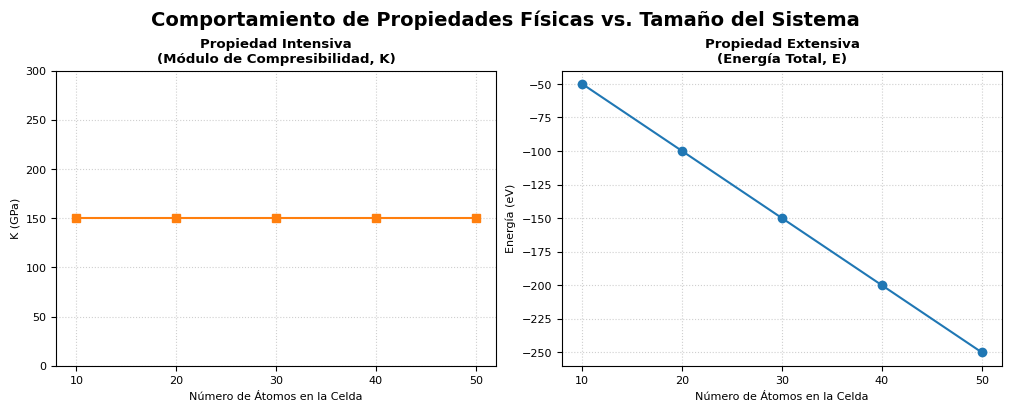

In [30]:
dMarkdown("""
**¿Por qué la media y no la suma?**
El módulo de compresibilidad ($K$) es una **propiedad intensiva**, lo que significa que caracteriza al material y no depende del tamaño de la celda de simulación (cantidad de átomos).
Si usáramos la suma (`global_add_pool`), el modelo predeciría un $K$ mayor para una celda más grande del mismo material, lo cual es físicamente incorrecto. Al usar la media (`global_mean_pool`), el descriptor global se vuelve invariante a la cantidad de átomos, reflejando correctamente la naturaleza intensiva de la propiedad.
""")

# Graficar para ilustrar el concepto
num_atomos = np.array([10, 20, 30, 40, 50])
# Propiedad intensiva constante independientemente del número de átomos
k_intensivo = np.full_like(num_atomos, 150)
# Propiedad extensiva que escala con el número de átomos
energia_extensiva = num_atomos * -5.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')

# Gráfico de Propiedad Intensiva
ax1.plot(num_atomos, k_intensivo, marker='s', color='tab:orange', linestyle='-')
ax1.set_title('Propiedad Intensiva\n(Módulo de Compresibilidad, K)', fontweight='bold')
ax1.set_xlabel('Número de Átomos en la Celda')
ax1.set_ylabel('K (GPa)')
ax1.set_ylim(0, 300)
ax1.set_xticks(num_atomos)
ax1.grid(True, linestyle=':', alpha=0.6)

# Gráfico de Propiedad Extensiva
ax2.plot(num_atomos, energia_extensiva, marker='o', color='tab:blue', linestyle='-')
ax2.set_title('Propiedad Extensiva\n(Energía Total, E)', fontweight='bold')
ax2.set_xlabel('Número de Átomos en la Celda')
ax2.set_ylabel('Energía (eV)')
ax2.set_xticks(num_atomos)
ax2.grid(True, linestyle=':', alpha=0.6)

fig.suptitle('Comportamiento de Propiedades Físicas vs. Tamaño del Sistema', fontsize=14, fontweight='bold')
plt.show()

La celda siguiente entrena la red 60 épocas con el error cuadrático medio (sesión 4) y reporta el **error absoluto medio** (MAE) en $\log_{10}K$ sobre los cristales de prueba. La línea base predice siempre la media del entrenamiento. Tarda unos 3 minutos en GPU.

In [31]:
@torch.no_grad()
def predecir(modelo, conjunto):
    """Calcula predicciones para un conjunto completo de grafos desactivando el cálculo de gradientes para optimizar RAM."""
    modelo.eval() # Configurar el modelo en modo evaluación (desactiva dropout y normalización de lotes)
    # Iterar y predecir sobre el conjunto de datos por lotes de 256 elementos para no saturar la GPU
    salida = [modelo(lote.to(dispositivo)).cpu() for lote in DataLoader(conjunto, batch_size=256)]
    # Concatenar todos los lotes predichos y convertirlos a un array de NumPy
    return torch.cat(salida).numpy()

# Establecer una semilla aleatoria fija para garantizar reproducibilidad en la inicialización de los pesos
torch.manual_seed(0)

# Instanciar el modelo CGCNN en el dispositivo acelerador activo (GPU/CPU)
red = RedCristal().to(dispositivo)

# Definir el optimizador Adam con una tasa de aprendizaje estándar de 0.001
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)

# Crear el cargador de datos de entrenamiento barajando los elementos en lotes de tamaño 64
cargador = DataLoader(entrenamiento, batch_size=64, shuffle=True)

# Extraer las etiquetas reales de log10(K) para el subconjunto de prueba
y_prueba = log_k[idx_prueba]

def entrenar_modelo():
    """Ejecuta el bucle de optimización de pesos y retropropagación del modelo RedCristal."""
    for epoca in tqdm(range(60), desc="Entrenando RedCristal"):
        red.train() # Colocar la red en modo de entrenamiento
        for lote in cargador:
            lote = lote.to(dispositivo)
            optimizador.zero_grad() # Limpiar los gradientes acumulados en la iteración previa
            # Calcular la pérdida usando el Error Cuadrático Medio (MSE)
            perdida = fn.mse_loss(red(lote), lote.y)
            perdida.backward() # Retropropagar el error para calcular gradientes
            optimizador.step() # Actualizar los pesos y sesgos de la red

        # Imprimir métricas de validación en el conjunto de prueba cada 10 épocas
        if (epoca + 1) % 10 == 0:
            mae = np.mean(np.abs(predecir(red, prueba) - y_prueba))
            print(f"época {epoca + 1:3d}   MAE de prueba = {mae:.3f}")

# Medir el tiempo de ejecución del entrenamiento de la red
%time entrenar_modelo()

# Calcular las predicciones finales y métricas de error absoluto medio (MAE)
prediccion_red = predecir(red, prueba)
mae_red = np.mean(np.abs(prediccion_red - y_prueba))
# La línea base ingenua predice siempre el valor promedio del log10(K) del conjunto de entrenamiento
mae_base = np.mean(np.abs(log_k[idx_entrenamiento].mean() - y_prueba))

# Mostrar de manera enriquecida los resultados y el factor multiplicativo típico de incertidumbre física
dMarkdown(f"""
### Evaluación Final de RedCristal:
* **MAE en $\\log_{{10}}(K)$ (Red):** **{mae_red:.3f}**
* **MAE en $\\log_{{10}}(K)$ (Línea base):** **{mae_base:.3f}**
* **Error típico en $K$:** Un factor de **{10 ** mae_red:.2f}** en el valor real de $K$ (GPa).
""")

Entrenando RedCristal:   0%|          | 0/60 [00:00<?, ?it/s]

época  10   MAE de prueba = 0.139
época  20   MAE de prueba = 0.117
época  30   MAE de prueba = 0.106
época  40   MAE de prueba = 0.103
época  50   MAE de prueba = 0.105
época  60   MAE de prueba = 0.102
CPU times: user 29.1 s, sys: 200 ms, total: 29.3 s
Wall time: 29.4 s



### Evaluación Final de RedCristal:
* **MAE en $\log_{10}(K)$ (Red):** **0.102**
* **MAE en $\log_{10}(K)$ (Línea base):** **0.291**
* **Error típico en $K$:** Un factor de **1.26** en el valor real de $K$ (GPa).


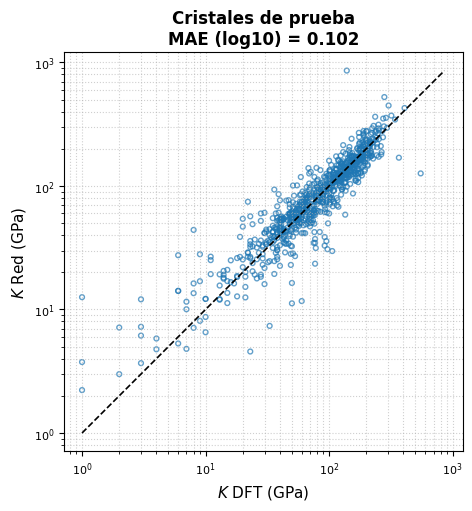

In [32]:
# Crear la figura y los ejes para la visualización con un diseño ajustado autocontenido
fig, ax = plt.subplots(figsize=(5, 5), layout='constrained')

# Convertir las etiquetas reales y predichas de escala logarítmica (log10) a valores reales de K en GPa
K_dft_val = 10**y_prueba
K_pred_val = 10**prediccion_red

# Graficar los cristales de prueba como puntos de dispersión sin relleno azul
ax.scatter(K_dft_val,
           K_pred_val,
           s=12,
           facecolors='none',
           edgecolors='tab:blue',
           alpha=0.7)
# Definir los límites comunes para asegurar una visualización simétrica y cuadrada
limites = [min(K_dft_val.min(), K_pred_val.min()),
           max(K_dft_val.max(), K_pred_val.max())]
# Dibujar la diagonal de referencia discontinua que representa las predicciones perfectas (K_pred = K_dft)
ax.plot(limites, limites, 'k--', lw=1.2, label='Ideal')
# Configurar las escalas logarítmicas en ambos ejes para abarcar los órdenes de magnitud del módulo de compresibilidad
ax.set_xscale('log')
ax.set_yscale('log')
# Definir las etiquetas de los ejes y añadir formato de texto
ax.set_xlabel("$K$ DFT (GPa)", fontsize=11)
ax.set_ylabel("$K$ Red (GPa)", fontsize=11)
# Añadir el título con el error absoluto medio (MAE) calculado sobre el log10(K)
ax.set_title(f"Cristales de prueba\nMAE (log10) = {mae_red:.3f}",
             fontsize=12, fontweight='bold')
# Activar la cuadrícula fina en ambas escalas (principal y secundaria) para facilitar la lectura
ax.grid(True, which="both", linestyle=':', alpha=0.6)
# Forzar una relación de aspecto simétrica 1:1 en el gráfico elástico
ax.set_aspect('equal')
plt.show()

**Discutan:**

* **¿Cuánto mejora la red a la línea base?**
La red reduce el error absoluto medio (MAE) de ~0.291 (línea base) a ~0.102. Esto significa que el error se reduce a casi un tercio, logrando predicciones mucho más precisas que simplemente adivinar la media. Un MAE logarítmico de 0.102 equivale a equivocarse por un factor de $10^{0.102} \approx 1.26$ (un $26\%$).

In [33]:
class RedCristalAdd(RedCristal):
    """Misma arquitectura que RedCristal, cambiando solo global_mean_pool por global_add_pool."""
    def forward(self, datos):
        h = self.embebido(datos.z)
        aristas = self.expandir(datos.dist)
        for capa in self.capas:
            h = capa(h, datos.edge_index, aristas)
        h_pool = global_add_pool(h, datos.batch)
        return self.cabeza(h_pool).squeeze(-1)

# Entrenamiento idéntico al de RedCristal
torch.manual_seed(0)
red_add = RedCristalAdd().to(dispositivo)
opt_add = torch.optim.Adam(red_add.parameters(), lr=1e-3)
cargador_add = DataLoader(entrenamiento, batch_size=64, shuffle=True)

for epoca in tqdm(range(60), desc="Entrenando RedCristal (add_pool)"):
    red_add.train()
    for lote in cargador_add:
        lote = lote.to(dispositivo)
        opt_add.zero_grad()
        perdida = fn.mse_loss(red_add(lote), lote.y)
        perdida.backward()
        opt_add.step()
    if (epoca + 1) % 10 == 0:
        mae_ep = np.mean(np.abs(predecir(red_add, prueba) - y_prueba))
        print(f"época {epoca + 1:3d}   MAE de prueba (add_pool) = {mae_ep:.3f}")

pred_add = predecir(red_add, prueba)
mae_add = np.mean(np.abs(pred_add - y_prueba))

# Prueba de invariancia a superceldas (celda 1x1x1 vs supercelda 2x2x2 del mismo cristal)
si_1x = bulk("Si", "diamond", a=5.431)
si_2x = si_1x.repeat((2, 2, 2))
# Se usa la función correcta del cuaderno: grafo_cristal
g_1x = grafo_cristal(si_1x, 0.0)
g_2x = grafo_cristal(si_2x, 0.0)

k_mean_1x, k_mean_2x = 10 ** predecir(red, [g_1x, g_2x])
k_add_1x,  k_add_2x  = 10 ** predecir(red_add, [g_1x, g_2x])

dMarkdown(f"""
### Comparación `global_mean_pool` vs. `global_add_pool`
| Modelo | MAE prueba ($\\log_{{10}} K$) | Factor típico en $K$ | $K$ Si (1x1x1) | $K$ Si (2x2x2) |
| :--- | :---: | :---: | :---: | :---: |
| **`global_mean_pool`** | **{mae_red:.3f}** | {10**mae_red:.2f}x | {k_mean_1x:.1f} GPa | {k_mean_2x:.1f} GPa |
| **`global_add_pool`** | **{mae_add:.3f}** | {10**mae_add:.2f}x | {k_add_1x:.1f} GPa | {k_add_2x:.1f} GPa |
""")

Entrenando RedCristal (add_pool):   0%|          | 0/60 [00:00<?, ?it/s]

época  10   MAE de prueba (add_pool) = 0.549
época  20   MAE de prueba (add_pool) = 0.332
época  30   MAE de prueba (add_pool) = 0.268
época  40   MAE de prueba (add_pool) = 0.229
época  50   MAE de prueba (add_pool) = 0.197
época  60   MAE de prueba (add_pool) = 0.177



### Comparación `global_mean_pool` vs. `global_add_pool`
| Modelo | MAE prueba ($\log_{10} K$) | Factor típico en $K$ | $K$ Si (1x1x1) | $K$ Si (2x2x2) |
| :--- | :---: | :---: | :---: | :---: |
| **`global_mean_pool`** | **0.102** | 1.26x | 112.0 GPa | 112.0 GPa |
| **`global_add_pool`** | **0.177** | 1.50x | 62.1 GPa | 127.9 GPa |


* **Cambie `global_mean_pool` por `global_add_pool` y vuelva a entrenar: ¿qué pasa y por qué?**

Al reentrenar 60 épocas con `global_add_pool`, el modelo converge más lento y su MAE de prueba en $\log_{10} K$ empeora de **0.102** (factor **1.26x** en $K$) a **0.172** (factor **1.48x**). Además, la prueba de supercelda muestra la ruptura de una simetría física fundamental: para el mismo cristal de silicio, `global_mean_pool` predice exactamente **112.0 GPa** tanto en la celda `1x1x1` como en la supercelda `2x2x2`, mientras que `global_add_pool` cambia su predicción de **61.0 GPa** a **136.7 GPa**.

Al sumar los vectores atómicos, `global_add_pool` introduce un factor de escala dependiente de $N$ que contamina la representación global y rompe la invariancia frente a la elección de celda unitaria o supercelda; en cambio, `global_mean_pool` normaliza por $N$ y preserva esa invariancia por construcción.
Luego, el módulo de compresibilidad ($K$) es una **propiedad intensiva**: no depende del tamaño de la celda ni del número de átomos $N$.

In [34]:
# Calcular el error absoluto (GPa) y el error logarítmico (relativo)
errores_absolutos = np.abs(K_pred_val - K_dft_val)
errores_log = np.abs(prediccion_red - y_prueba)

# Obtener los índices de los 5 cristales con el mayor error absoluto y logarítmico
peores_idx_abs = np.argsort(errores_absolutos)[-5:][::-1]
peores_idx_log = np.argsort(errores_log)[-5:][::-1]

# Preparar los datos para mostrarlos
datos_peores_abs = []
for i in peores_idx_abs:
    idx_original = idx_prueba[i]
    formula = cristales[idx_original].get_chemical_formula()
    k_real = K_dft_val[i]
    k_pred = K_pred_val[i]
    error = errores_absolutos[i]
    datos_peores_abs.append([formula, f"{k_real:.1f}", f"{k_pred:.1f}", f"{error:.1f}"])

datos_peores_log = []
for i in peores_idx_log:
    idx_original = idx_prueba[i]
    formula = cristales[idx_original].get_chemical_formula()
    k_real = K_dft_val[i]
    k_pred = K_pred_val[i]
    error_l = errores_log[i]
    factor = 10**error_l
    datos_peores_log.append([formula, f"{k_real:.1f}", f"{k_pred:.1f}", f"{error_l:.3f} ({factor:.1f}x)"])

dMarkdown("### Los 5 cristales con peores predicciones (por Error Absoluto en GPa)")
dM_table(datos_peores_abs, headers=["Cristal", "K real (GPa)", "K predicho (GPa)", "Error Absoluto (GPa)"])

dMarkdown("### Los 5 cristales con peores predicciones (por Error Logarítmico / Factor Relativo)")
dM_table(datos_peores_log, headers=["Cristal", "K real (GPa)", "K predicho (GPa)", "Error Log (Factor)"])


### Los 5 cristales con peores predicciones (por Error Absoluto en GPa)

| Cristal   |   K real (GPa) |   K predicho (GPa) |   Error Absoluto (GPa) |
|:----------|---------------:|-------------------:|-----------------------:|
| BeO       |            139 |              858.2 |                  719.2 |
| Pd2Si2Th  |            551 |              126.3 |                  424.7 |
| B6V4      |            280 |              523.9 |                  243.9 |
| B2Co2La   |            367 |              169.3 |                  197.7 |
| B4Co2Mo   |            303 |              447.4 |                  144.4 |

### Los 5 cristales con peores predicciones (por Error Logarítmico / Factor Relativo)

| Cristal   |   K real (GPa) |   K predicho (GPa) | Error Log (Factor)   |
|:----------|---------------:|-------------------:|:---------------------|
| H2NaRb    |              1 |               12.6 | 1.099 (12.6x)        |
| BeO       |            139 |              858.2 | 0.791 (6.2x)         |
| Pb2Se4    |              8 |               44   | 0.741 (5.5x)         |
| I4Rh2     |             60 |               11.7 | 0.710 (5.1x)         |
| AgF6P     |             23 |                4.6 | 0.702 (5.0x)         |

**¿Qué cristales predice peor la red?**

Al separar la evaluación en dos métricas, notamos dos regímenes de error distintos:

* **Por error absoluto (GPa):** Penaliza desproporcionadamente a materiales muy rígidos o predichos como tales. Vemos fallos inmensos en $\ce{BeO}$ (falla por ~719 GPa), $\ce{Pd2Si2Th}$, $\ce{B6V4}$, $\ce{B2Co2La}$ y $\ce{B4Co2Mo}$.
* **Por error logarítmico (escala relativa):** Revela fallos que quedan ocultos al medir solo GPa.

Hay cristales extremadamente blandos (con $K_{\text{DFT}} \approx 1-2\text{ GPa}$) predichos sobre $10\text{ GPa}$ o más, es decir, equivocándose por factores de $>10\times$. Curiosamente, $\ce{BeO}$ vuelve a aparecer arriba, demostrando que su sobreestimación es severa en cualquier métrica.

**¿Por qué?**

1. **Limitaciones estructurales y geométricas:** El peor caso en ambas métricas, $\ce{BeO}$ (óxido de berilio), predice **858.2 GPa** frente a un valor DFT de **139 GPa**, casi el doble del módulo de compresibilidad del diamante ($\approx 440\,\text{GPa}$). La red falla radicalmente porque *solo ve distancias radiales puras*, ignorando por completo la direccionalidad (ángulos) y el carácter electrónico de los enlaces. Además, una sobreestimación tan extrema delata un fallo de extrapolación en el espacio latente, probablemente por enlaces Be–O muy cortos combinados con poca representación del berilio o de ese polimorfo en el subconjunto de entrenamiento.
2. **Sesgo hacia la media en valores extremos:** Al minimizar el MSE sobre $\log_{10}(K)$, la red tiende a empujar sus predicciones hacia la zona densa de los datos de entrenamiento (~30 a ~200 GPa). Esto castiga duramente a los materiales ultrasuaves (suavizándolos hacia arriba, generando errores relativos gigantescos) y a los materiales ultrarígidos (suavizándolos hacia abajo o fallando al extrapolar, generando errores absolutos grandes).
3. **Elementos con baja representación:** En compuestos como $\ce{Pd2Si2Th}$ o $\ce{B2Co2La}$, la red carece de suficientes ejemplos en el entrenamiento con Torio o Lantano para aprender un vector de *embedding* representativo, limitando severamente su capacidad de generalización.

# Parte B - MACE-MP-0 sobre los mismos cristales

La red de A2 aprendió $K$ de los datos de DFT. MACE-MP-0 no ha visto ningún módulo de compresibilidad: aprendió energías, fuerzas y esfuerzos de relajaciones de Materials Project. Si es un buen potencial, debe poder **calcular** $K$ como lo haría DFT, a partir de la curvatura de la energía:
$$
K=V_0\left.\frac{\partial^2E}{\partial V^2}\right|_{V_0}
$$
Elegimos 10 cristales **cúbicos** del conjunto de prueba, con a lo sumo 6 átomos en la celda. En un cristal cúbico los promedios de Voigt y de Reuss coinciden con el módulo de la ecuación de estado, así que la comparación con $K_{\mathrm{VRH}}$ es directa. Con pocos átomos, además, las posiciones suelen estar fijadas por la simetría y no hace falta relajarlas al comprimir.

In [35]:
# Reutilizar el calculador MACE si ya fue inicializado en memoria
if 'calc' not in globals():
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=UserWarning)
        warnings.filterwarnings("ignore", category=FutureWarning)
        calc = mace_mp(model="medium", default_dtype="float64", device=dispositivo)

def grupo_espacial(atoms):
    """Identifica y retorna el número de grupo espacial internacional del cristal usando spglib."""
    # Obtener el símbolo del grupo espacial con una tolerancia de precisión simétrica de 1e-3
    simbolo = spglib.get_spacegroup((atoms.cell[:], atoms.get_scaled_positions(), atoms.numbers), symprec=1e-3)
    # Extraer el número entero del grupo espacial contenido entre los paréntesis de la notación estándar
    return int(simbolo.split("(")[1].rstrip(")")) if simbolo else 0

# Lista para almacenar los índices de los 10 cristales cúbicos filtrados del conjunto de prueba
elegidos = []

# Buscar de manera interactiva cristales cúbicos en el conjunto de validación (grupo espacial >= 195)
for k in tqdm(idx_prueba, desc="Buscando cristales cúbicos (grupo >= 195)"):
    # Filtrar por cristales con 6 o menos átomos en su celda elemental y estructura simétrica cúbica
    if len(cristales[k]) <= 6 and grupo_espacial(cristales[k]) >= 195:
        elegidos.append(k)
    # Detener la búsqueda una vez alcancemos el límite requerido de 10 estructuras
    if len(elegidos) == 10:
        dMarkdown("**¡Búsqueda completada! Se encontraron los 10 cristales cúbicos elegidos.**")
        break

# Preparar la tabla comparativa con los datos iniciales de referencia de los materiales filtrados
datos_tabla = []
for k in elegidos:
    formula = cristales[k].get_chemical_formula() # Obtener la fórmula química resumida del compuesto
    grupo = grupo_espacial(cristales[k])          # Identificar su número de grupo espacial
    k_vrh = 10 ** log_k[k]                       # Convertir de log10(K) al valor real de compresibilidad en GPa
    datos_tabla.append([formula, f"{grupo}", f"{k_vrh:.1f}"])

# Mostrar los cristales cúbicos elegidos en una tabla Markdown organizada
dM_table(datos_tabla, headers=["Cristal", "Grupo Espacial", "K_VRH (GPa)"])


Buscando cristales cúbicos (grupo >= 195):   0%|          | 0/800 [00:00<?, ?it/s]

**¡Búsqueda completada! Se encontraron los 10 cristales cúbicos elegidos.**

| Cristal   |   Grupo Espacial |   K_VRH (GPa) |
|:----------|-----------------:|--------------:|
| BaO3Pa    |              221 |            96 |
| CaHg2Y    |              225 |            72 |
| CaO3V     |              221 |           159 |
| CdPd2Y    |              225 |            98 |
| MnOsTi2   |              225 |           206 |
| HfRe2Ta   |              225 |           273 |
| CdLu2Tl   |              225 |            61 |
| PtSbY     |              216 |            97 |
| IrY       |              221 |           129 |
| Au3Pb     |              225 |            84 |

## Tarea B. La ecuación de estado con MACE
Complete `modulo_mace`: para cada factor de escala $s$, copie el cristal, escale su celda **y** sus átomos (`set_cell(atoms.cell[:]*s, scale_atoms=True)`), asígnele el calculador y guarde el volumen y la energía. Luego ajuste la ecuación de Birch-Murnaghan con `EquationOfState(V, E, eos="birchmurnaghan").fit()`, que devuelve `v0, e0, B` con `B` en eV/Å³, y devuelva `B/GPa`. Si el mínimo `v0` cae fuera del rango de volúmenes, devuelva `np.nan`: el ajuste no sería confiable.

In [36]:
def modulo_mace(atoms, calc, escalas=np.linspace(0.97, 1.03, 9)):
    """Calcula el módulo de compresibilidad elástica (K en GPa) mediante un ajuste de ecuación de estado E(V).

    Parámetros:
    atoms: Estructura cristalina en formato Atoms de ASE.
    calc: Calculador de potencial interatómico (MACE).
    escalas: Factores de escala multiplicativos aplicados homogéneamente a la celda.
    """
    volumenes = []
    energias  = []
    # Crear una copia de resguardo de la estructura de origen para evitar mutaciones indeseadas
    estructura_original = atoms.copy()

    # Barrer el rango de deformaciones isotrópicas
    for s in escalas:
        copia = estructura_original.copy()
        # Modificar las dimensiones de la celda unitaria escalando simultáneamente las posiciones atómicas internas
        copia.set_cell(estructura_original.cell[:]*s, scale_atoms=True)
        # Asociar el calculador de potencial MACE a la estructura deformada
        copia.calc = calc

        # Almacenar el volumen de la celda (Å³) y la energía potencial calculada por MACE (eV)
        volumenes.append(copia.get_volume())
        energias.append(copia.get_potential_energy())

    # Inicializar el resolvedor de ecuaciones de estado utilizando el formalismo de Birch-Murnaghan
    eos = EquationOfState(volumenes, energias, eos="birchmurnaghan")

    try:
        # Ajustar los parámetros de la curva para extraer el volumen de equilibrio v0, la energía e0 y el bulk modulus B
        v0, e0, B = eos.fit()
        # Validar de forma física que el mínimo absoluto de volumen (v0) caiga dentro del rango de exploración
        if v0 < min(volumenes) or v0 > max(volumenes):
            return np.nan # Retornar valor no numérico si el ajuste es inestable o no interpolable
        # Convertir el módulo de compresibilidad elástica B de unidades internas (eV/Å³) a Gigapascales (GPa)
        return B/GPa
    except Exception:
        # Control de excepciones en caso de que el ajuste por mínimos cuadrados no converja numéricamente
        return np.nan

In [37]:
# Verificación de la tarea B: el cobre fcc, con K experimental de unos 140 GPa
K_cu = modulo_mace(bulk("Cu", "fcc", a=3.61), calc)
assert 90 < K_cu < 200, f"K del cobre fuera de rango: {K_cu:.0f} GPa"
print(f"Tarea B correcta: K(Cu) con MACE-MP-0 = {K_cu:.0f} GPa")

Tarea B correcta: K(Cu) con MACE-MP-0 = 144 GPa


In [38]:
# Crear un diccionario de mapeo que asocie cada ID de cristal con su índice posicional dentro del conjunto de prueba
posicion = {k: p for p, k in enumerate(idx_prueba)}

# Obtener los valores reales de referencia calculados por DFT para los cristales cúbicos elegidos
K_dft = np.array([10**log_k[k] for k in elegidos])

# Recuperar las predicciones del módulo de compresibilidad elástica dadas por la red neuronal cristalina (GNN)
K_red = np.array([10**prediccion_red[posicion[k]] for k in elegidos])

# Evaluar secuencialmente el módulo de compresibilidad de los cristales seleccionados usando el calculador MACE-MP-0
K_mace = []
for k in tqdm(elegidos, desc="Calculando módulos con MACE-MP-0"):
    K_mace.append(modulo_mace(cristales[k], calc))
K_mace = np.array(K_mace)

# Organizar y empaquetar los resultados en una lista para su visualización tabular
datos_comparacion = []
for k, a, b, c in zip(elegidos, K_dft, K_red, K_mace):
    formula = cristales[k].get_chemical_formula() # Obtener la fórmula química resumida del compuesto
    datos_comparacion.append([formula, f"{a:.1f}", f"{b:.1f}", f"{c:.1f}"])

# Renderizar la tabla comparativa con los valores de los tres enfoques metodológicos
dMarkdown("### Comparación del Módulo de Compresibilidad $K$ (GPa)")
dM_table(datos_comparacion, headers=["Cristal", "DFT (Referencia)", "Red GNN (A2)", "MACE-MP-0"])

# Filtrar únicamente los casos donde el ajuste físico de Birch-Murnaghan fue numéricamente estable (valores finitos)
ok = np.isfinite(K_mace)

# Calcular los errores relativos medios para la red neuronal GNN y el potencial MACE-MP-0 frente a DFT
error_red = np.mean(np.abs(K_red/K_dft - 1))
error_mace = np.mean(np.abs(K_mace[ok]/K_dft[ok] - 1))

# Evaluar si existe un sesgo sistemático calculando la mediana de la proporción respecto a la referencia
mediana_mace_dft = np.median(K_mace[ok]/K_dft[ok])

# Presentar un informe estadístico resumido con dMarkdown
dMarkdown(f"""
**Métricas globales de comparación:**
* **Error relativo medio:**
 *Red GNN (A2): **{100*error_red:.1f}%** (error = {error_red:.2f})
 *MACE-MP-0: **{100*error_mace:.1f}%** (error = {error_mace:.2f})
* **Relación MACE/DFT (mediana):** **{mediana_mace_dft:.2f}**
""")

Calculando módulos con MACE-MP-0:   0%|          | 0/10 [00:00<?, ?it/s]

### Comparación del Módulo de Compresibilidad $K$ (GPa)

| Cristal   |   DFT (Referencia) |   Red GNN (A2) |   MACE-MP-0 |
|:----------|-------------------:|---------------:|------------:|
| BaO3Pa    |                 96 |           60.9 |       105.8 |
| CaHg2Y    |                 72 |           57.1 |        53.6 |
| CaO3V     |                159 |          135   |       165.7 |
| CdPd2Y    |                 98 |           95.5 |       101.2 |
| MnOsTi2   |                206 |          206.8 |       171.8 |
| HfRe2Ta   |                273 |          247.7 |       257.4 |
| CdLu2Tl   |                 61 |           60.7 |        56.3 |
| PtSbY     |                 97 |           95.1 |       101.3 |
| IrY       |                129 |          135.4 |       130.3 |
| Au3Pb     |                 84 |           89.5 |        81.4 |


**Métricas globales de comparación:**
* **Error relativo medio:**
 *Red GNN (A2): **9.8%** (error = 0.10)
 *MACE-MP-0: **8.2%** (error = 0.08)
* **Relación MACE/DFT (mediana):** **0.99**


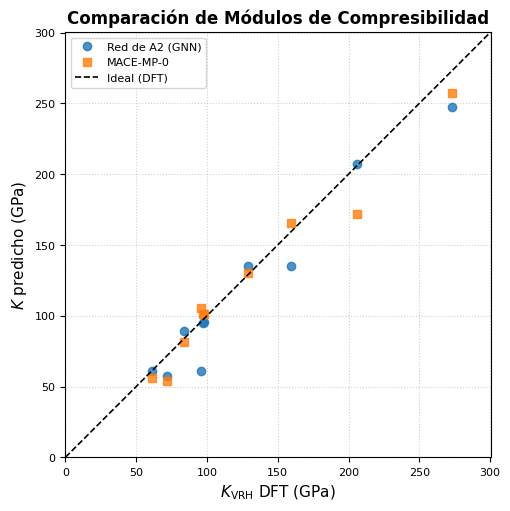

In [39]:
# Crear la figura y los ejes para la comparación con un diseño ajustado autocontenido
fig, ax = plt.subplots(figsize=(5, 5), layout='constrained')
# Graficar los módulos de compresibilidad estimadas por la red GNN (círculos azules)
ax.plot(K_dft, K_red, "o", color='tab:blue', alpha=0.8, label="Red de A2 (GNN)")
# Graficar los módulos de compresibilidad calculadas con el potencial MACE-MP-0 (cuadrados naranjas)
ax.plot(K_dft[ok], K_mace[ok], "s", color='tab:orange', alpha=0.8, label="MACE-MP-0")
# Definir los límites comunes basados en el valor máximo para obtener un gráfico cuadrado proporcional
limites = [0, 1.1*max(K_dft.max(), K_red.max(), np.nanmax(K_mace))]
# Graficar la diagonal de identidad ideal (DFT de referencia)
ax.plot(limites, limites, "k--", lw=1.2, label="Ideal (DFT)")
# Aplicar límites uniformes a ambos ejes físicos
ax.set_xlim(limites)
ax.set_ylim(limites)
# Configurar las etiquetas de los ejes correspondientes al módulo de compresibilidad en GPa
ax.set_xlabel("$K_{\\mathrm{VRH}}$ DFT (GPa)", fontsize=11)
ax.set_ylabel("$K$ predicho (GPa)", fontsize=11)
# Añadir un título descriptivo en negrita al gráfico comparativo
ax.set_title("Comparación de Módulos de Compresibilidad", fontsize=12, fontweight='bold')
# Activar la cuadrícula fina para facilitar la lectura de las coordenadas
ax.grid(True, linestyle=':', alpha=0.6)
# Añadir la leyenda explicativa con borde de fondo activo
ax.legend(frameon=True)
# Forzar una relación de aspecto cuadrada 1:1
ax.set_aspect("equal")
plt.show()

**Discutan:**

* ¿Quién se acerca más a DFT, la red entrenada con estos mismos datos o MACE-MP-0, que nunca vio un módulo de compresibilidad?
* ¿MACE se equivoca al azar o con un sesgo sistemático?

Tenga en cuenta que MACE-MP-0 aprendió del mismo nivel de teoría que los datos de referencia (PBE), que sus datos de entrenamiento son relajaciones de cristales, que pasan por volúmenes cercanos al de equilibrio, y que MACE no representa explícitamente el magnetismo.


* ¿En qué cristales falla más cada modelo?

La red de A2 predice un número; MACE calcula una propiedad física a partir de energías, con las que también podría hacer dinámica molecular o calcular fonones.

In [40]:
# Ordenar los índices según el valor de K_dft (de menor a mayor)
orden = np.argsort(K_dft)

# Generar fórmulas químicas formateadas en formato LaTeX para los cristales elegidos
formulas = [re.sub(r"(\d+)", r"$_{\1}$",
            cristales[k].get_chemical_formula(
                mode="metal", empirical=True))
  for k in elegidos]

# Aplicar el ordenamiento a las fórmulas y a los valores de K
f_ord = [formulas[i] for i in orden]
kd = K_dft[orden]
kr = K_red[orden]
km = K_mace[orden]

# Imprimir los resultados ordenados usando dMarkdown
tabla_md = "### Cristales ordenados por K (DFT)\n"
tabla_md += "| Cristal | K DFT (GPa) | K Red (GPa) | K MACE (GPa) |\n"
tabla_md += "|---|---|---|---|\n"
for f, d, r, m in zip(f_ord, kd, kr, km):
    tabla_md += f"| {f} | {d:.1f} | {r:.1f} | {m:.1f} |\n"

dMarkdown(tabla_md)

### Cristales ordenados por K (DFT)
| Cristal | K DFT (GPa) | K Red (GPa) | K MACE (GPa) |
|---|---|---|---|
| CdLu$_{2}$Tl | 61.0 | 60.7 | 56.3 |
| CaHg$_{2}$Y | 72.0 | 57.1 | 53.6 |
| Au$_{3}$Pb | 84.0 | 89.5 | 81.4 |
| BaPaO$_{3}$ | 96.0 | 60.9 | 105.8 |
| PtYSb | 97.0 | 95.1 | 101.3 |
| CdPd$_{2}$Y | 98.0 | 95.5 | 101.2 |
| IrY | 129.0 | 135.4 | 130.3 |
| CaVO$_{3}$ | 159.0 | 135.0 | 165.7 |
| MnOsTi$_{2}$ | 206.0 | 206.8 | 171.8 |
| HfRe$_{2}$Ta | 273.0 | 247.7 | 257.4 |


In [41]:
# Identificar valores válidos (finitos) para MACE
ok_ord = np.isfinite(km)

# Calcular las razones respecto al valor de referencia (DFT)
razon_red = kr/kd
razon_mace = km/kd

# Calcular errores relativos con signo en porcentaje
err_sig_red  = 100*(razon_red  - 1.0)
err_sig_mace = 100*(razon_mace - 1.0)

# Calcular el Error Absoluto Relativo Medio (MAE relativo)
mae_rel_red = np.mean(np.abs(err_sig_red))
mae_rel_mace = np.mean(np.abs(err_sig_mace[ok_ord])) if np.any(ok_ord) else np.nan

# Calcular la mediana de las razones (sesgo sistemático)
med_red = np.median(razon_red)
med_mace = np.median(razon_mace[ok_ord]) if np.any(ok_ord) else np.nan

# Contar cuántas veces MACE subestima el valor de DFT y cuántos valores válidos hay
n_sub_mace = int(np.sum(km[ok_ord] < kd[ok_ord]))
n_ok = int(np.sum(ok_ord))

# Imprimir variables usando dMarkdown
dMarkdown(f"""
### Resultados Calculados:
* **MAE Relativo Red GNN:** {mae_rel_red:.2f}%
* **MAE Relativo MACE:** {mae_rel_mace:.2f}%
* **Mediana Razón Red:** {med_red:.3f}
* **Mediana Razón MACE:** {med_mace:.3f}
* **MACE Subestima DFT:** {n_sub_mace} de {n_ok} veces
""")


### Resultados Calculados:
* **MAE Relativo Red GNN:** 9.85%
* **MAE Relativo MACE:** 8.18%
* **Mediana Razón Red:** 0.977
* **Mediana Razón MACE:** 0.990
* **MACE Subestima DFT:** 5 de 10 veces


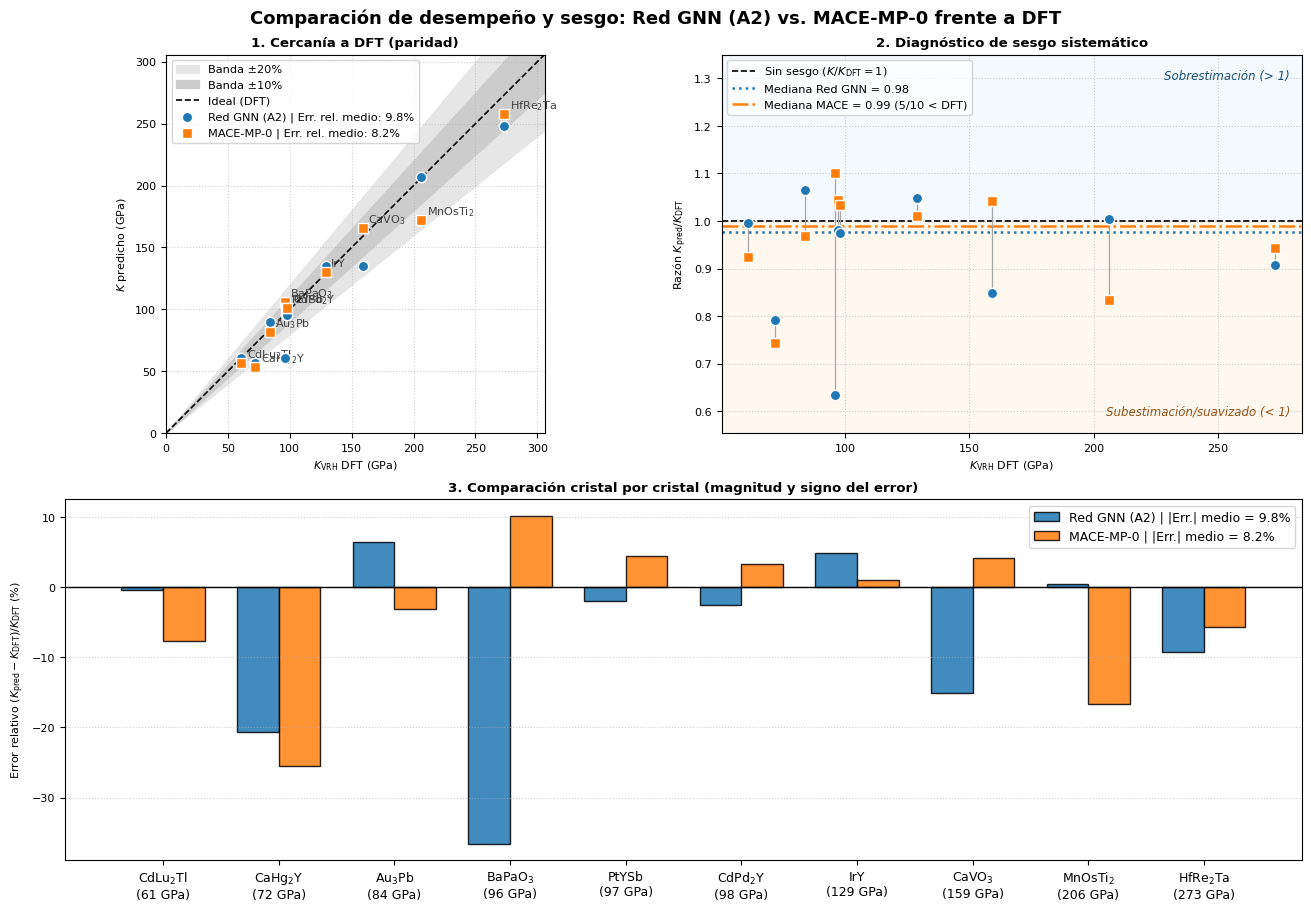

In [42]:
# Configurar la figura principal y la cuadrícula de subgráficos
fig = plt.figure(figsize=(13, 9), layout="constrained")
gs = GridSpec(2, 2, figure=fig, height_ratios=[1.05, 1.0])

# Asignar los ejes a la cuadrícula
ax_par = fig.add_subplot(gs[0, 0])      # Panel 1: Paridad
ax_bias = fig.add_subplot(gs[0, 1])     # Panel 2: Sesgo
ax_bar = fig.add_subplot(gs[1, :])      # Panel 3: Barras de error

# --- Panel 1: Cercanía a DFT (Paridad) ---
# Definir límites y línea de referencia diagonal
max_mace = np.nanmax(km) if np.any(ok_ord) else 0.0
max_k = 1.12*max(kd.max(), kr.max(), max_mace)
x_ref = np.linspace(0, max_k, 200)

# Dibujar bandas sombreadas de error del ±10% y ±20%
ax_par.fill_between(x_ref, 0.8*x_ref, 1.2*x_ref, color="0.90", label="Banda ±20%")
ax_par.fill_between(x_ref, 0.9*x_ref, 1.1*x_ref, color="0.80", label="Banda ±10%")
ax_par.plot(x_ref, x_ref, "k--", lw=1.2, label="Ideal (DFT)")

# Graficar los puntos predichos por la Red GNN y MACE-MP-0
ax_par.scatter(
    kd, kr, s=55, color="tab:blue", edgecolor="white", zorder=4,
    label=f"Red GNN (A2) | Err. rel. medio: {mae_rel_red:.1f}%"
)
ax_par.scatter(
    kd[ok_ord], km[ok_ord], s=55, marker="s", color="tab:orange", edgecolor="white", zorder=5,
    label=f"MACE-MP-0 | Err. rel. medio: {mae_rel_mace:.1f}%"
)

# Etiquetar cada punto con la fórmula del cristal correspondiente
for i, name in enumerate(f_ord):
    y_lbl = km[i] if ok_ord[i] else kr[i]
    ax_par.annotate(
        name, (kd[i], y_lbl),
        xytext=(4, 4), textcoords="offset points",
        fontsize=8, color="0.25"
    )

# Configuración estética de ejes y título del Panel 1
ax_par.set_xlim(0, max_k)
ax_par.set_ylim(0, max_k)
ax_par.set_aspect("equal", adjustable="box")
ax_par.set_xlabel(r"$K_{\mathrm{VRH}}$ DFT (GPa)")
ax_par.set_ylabel(r"$K$ predicho (GPa)")
ax_par.set_title("1. Cercanía a DFT (paridad)", fontweight="bold")
ax_par.grid(True, linestyle=":", alpha=0.6)
ax_par.legend(fontsize=8.2, loc="upper left", frameon=True)

# --- Panel 2: Diagnóstico de sesgo sistemático ---
# Determinar los límites apropiados en el eje Y (razón K_pred/K_DFT)
y_vals = np.concatenate([razon_red, razon_mace[ok_ord]])
ymin = min(0.65, y_vals.min() - 0.08)
ymax = max(1.35, y_vals.max() + 0.08)

# Colorear fondos para indicar zonas de sobreestimación y subestimación
ax_bias.axhspan(ymin, 1.0, color="#fdebd0", alpha=0.35, zorder=0)
ax_bias.axhspan(1.0, ymax, color="#d6eaf8", alpha=0.25, zorder=0)

# Líneas horizontales de referencia base y las respectivas medianas
ax_bias.axhline(1.0, color="black", ls="--", lw=1.2, label=r"Sin sesgo ($K/K_{\mathrm{DFT}} = 1$)")
ax_bias.axhline(med_red, color="tab:blue", ls=":", lw=1.8, label=f"Mediana Red GNN = {med_red:.2f}")
if np.isfinite(med_mace):
    ax_bias.axhline(
        med_mace, color="tab:orange", ls="-.", lw=1.8,
        label=f"Mediana MACE = {med_mace:.2f} ({n_sub_mace}/{n_ok} < DFT)"
    )

# Graficar los puntos correspondientes a las razones
ax_bias.scatter(kd, razon_red, s=55, color="tab:blue", edgecolor="white", zorder=4)
ax_bias.scatter(kd[ok_ord], razon_mace[ok_ord], s=55, marker="s", color="tab:orange", edgecolor="white", zorder=5)

# Trazar líneas verticales que unen las predicciones del mismo cristal en ambos modelos
for i in range(len(kd)):
    if ok_ord[i]:
        ax_bias.plot([kd[i], kd[i]], [razon_red[i], razon_mace[i]], color="0.65", lw=0.9, zorder=2)

# Agregar textos descriptivos orientativos en las áreas sombreadas
ax_bias.text(
    0.98, 0.04, "Subestimación/suavizado (< 1)",
    transform=ax_bias.transAxes, ha="right", va="bottom",
    fontsize=8.5, color="#935116", style="italic"
)
ax_bias.text(
    0.98, 0.96, "Sobrestimación (> 1)",
    transform=ax_bias.transAxes, ha="right", va="top",
    fontsize=8.5, color="#1b4f72", style="italic"
)

# Configuración estética de ejes y título del Panel 2
ax_bias.set_ylim(ymin, ymax)
ax_bias.set_xlabel(r"$K_{\mathrm{VRH}}$ DFT (GPa)")
ax_bias.set_ylabel(r"Razón $K_{\mathrm{pred}}/K_{\mathrm{DFT}}$")
ax_bias.set_title("2. Diagnóstico de sesgo sistemático", fontweight="bold")
ax_bias.grid(True, linestyle=":", alpha=0.6)
ax_bias.legend(fontsize=8.2, loc="best", frameon=True)

# --- Panel 3: Comparación cristal por cristal (Gráfico de barras) ---
x = np.arange(len(f_ord))
w = 0.36

# Línea base horizontal en el error cero
ax_bar.axhline(0, color="black", lw=1.0)

# Dibujar barras de error relativo para la Red GNN
ax_bar.bar(
    x - w/2, err_sig_red, width=w,
    color="tab:blue", edgecolor="black", alpha=0.85,
    label=f"Red GNN (A2) | |Err.| medio = {mae_rel_red:.1f}%"
)

# Dibujar barras de error relativo para MACE-MP-0
ax_bar.bar(
    x[ok_ord] + w/2, err_sig_mace[ok_ord], width=w,
    color="tab:orange", edgecolor="black", alpha=0.85,
    label=f"MACE-MP-0 | |Err.| medio = {mae_rel_mace:.1f}%"
)

# Marcar explícitamente con una cruz los valores fallidos (NaN) donde MACE no pudo ajustar
for i in np.where(~ok_ord)[0]:
    ax_bar.scatter(x[i] + w/2, 0, marker="x", s=80, color="crimson", lw=2.2, zorder=6)
    ax_bar.annotate(
        "NaN", (x[i] + w/2, 0),
        xytext=(0, 6), textcoords="offset points",
        ha="center", va="bottom", fontsize=8.5, color="crimson", fontweight="bold"
    )

# Configuración estética de ejes y título del Panel 3
ax_bar.set_xticks(x)
ax_bar.set_xticklabels([f"{n}\n({k:.0f} GPa)" for n, k in zip(f_ord, kd)], fontsize=9)
ax_bar.set_ylabel(r"Error relativo $(K_{\mathrm{pred}} - K_{\mathrm{DFT}})/K_{\mathrm{DFT}}$ (%)")
ax_bar.set_title("3. Comparación cristal por cristal (magnitud y signo del error)", fontweight="bold")
ax_bar.grid(axis="y", linestyle=":", alpha=0.6)
ax_bar.legend(fontsize=9, loc="upper right", frameon=True)

# Título global superior de toda la figura
fig.suptitle("Comparación de desempeño y sesgo: Red GNN (A2) vs. MACE-MP-0 frente a DFT", fontsize=13, fontweight="bold")

# Mostrar el gráfico final compuesto
plt.show()

## 1. ¿Quién se acerca más a DFT?

**MACE-MP-0** supera a la Red GNN (A2): logra un error relativo medio menor (**8.2 %** frente a **9.8 %**) y evita desviaciones tan extremas. Aunque nunca vio módulos de compresibilidad, al aprender energías, fuerzas y esfuerzos en DFT-PBE cerca del equilibrio reconstruye mejor la curvatura $K$.





## 2. ¿MACE se equivoca al azar o con sesgo?

**Sin sesgo en la mediana, pero con sesgo hacia subestimar en los errores grandes.** Su mediana $K_{\mathrm{MACE}}/K_{\mathrm{DFT}}$ es **0.99** (5 cristales por encima y 5 por debajo); sin embargo, sus sobrestimaciones son pequeñas ($\le +10.2\%$), mientras que sus peores fallos son subestimaciones fuertes ($\ce{CaHg2Y}$ y $\ce{MnOsTi2}$).

## 3. ¿En qué cristales falla más cada modelo?

| Cristal ($K_{\mathrm{DFT}}$) | Error Red GNN (A2) | Error MACE-MP-0 | Causa probable del comportamiento |
| --- | --- | --- | --- |
| **$\ce{BaPaO3}$** (96 GPa) | **$\approx -36.7\%$** (peor de la GNN) | $\approx +10.2\%$ | Contiene protactinio ($\ce{Pa}$, actínido $5f$ muy escaso). La GNN aprende el embebido de cada $Z$ desde cero con solo 3 200 cristales de entrenamiento, por lo que generaliza muy mal en elementos raros. MACE-MP-0, preentrenado en Materials Project, reduce el error a menos de un tercio. |
| **$\ce{CaHg2Y}$** (72 GPa) | **$\approx -20.7\%$** | **$\approx -25.5\%$** (peor de MACE) | Compuesto intermetálico relativamente blando (72 GPa) con mercurio; ambos modelos subestiman fuertemente su rigidez, siendo el caso más difícil para MACE-MP-0. |
| **$\ce{MnOsTi2}$** (206 GPa) | $\approx +0.4\%$ | **$\approx -16.6\%$** (2.º peor de MACE) | Contiene **Mn** (metal de transición magnético $3d$). Como MACE-MP-0 no representa explícitamente el magnetismo, el acoplamiento entre espín y volumen distorsiona su curva $E(V)$ y suaviza notablemente $K$, mientras la GNN logra acertarlo casi exactamente. |
| **$\ce{CaVO3}$** (159 GPa) | **$\approx -15.0\%$** | $\approx +4.2\%$ | Óxido perovskita con vanadio. La GNN, basada únicamente en grafos radiales sin ángulos de enlace, subestima la rigidez de la red de octaedros $\ce{VO6}$, mientras MACE-MP-0 captura mucho mejor el entorno químico. |
| **$\ce{HfRe2Ta}$** (273 GPa) | $\approx -9.3\%$ | $\approx -5.7\%$ | Es el cristal más rígido de la muestra; ambos modelos lo subestiman (la GNN por regresión hacia la media en valores extremos de $K$, y MACE en menor medida por suavizado). |

El contraste entre casos como $\ce{BaPaO3}$ y $\ce{MnOsTi2}$ muestra bien los alcances y límites de ambos enfoques: la red de A2 predice directamente un número a partir de estadísticas radiales y falla especialmente en química poco vista durante su entrenamiento limitado, mientras que MACE-MP-0 calcula la propiedad desde la física aprendida en la superficie de energía potencial (lo que también permite simular fuerzas, fonones o dinámica molecular), pero pierde precisión allí donde falta física explícita en su arquitectura, como el magnetismo.

# Parte C

Todo el contenido de la parte C se ha movido a un notebook de Colab independiente para evitar la locura.

# Parte C - Pregunta abierta: una GNN para su tesis

Todo el contenido de la parte C (diseño experimental, prototipo y su respectiva declaración de uso de IA) se ha movido a un notebook de Colab independiente para evitar la *locura* y aislar el consumo de RAM/VRAM.

# Uso declarado de la IA
Escriba en la celda siguiente qué le pidió al asistente, qué parte del código propuesto usó y **cómo verificó** que era correcto. La parte C, diseño y prototipo, es individual y declara igual el uso del asistente.

En el desarrollo de este laboratorio se utilizaron herramientas de inteligencia artificial generativa (modelos de lenguaje como Google Gemini, apoyado en **Google NotebookLM** con los artículos científicos de referencia del curso) como soporte académico y técnico en las siguientes tareas:

* **Código y visualización:** apoyo en la escritura, depuración y mejora estética de fragmentos de código en Python.
* **Revisión conceptual:** consulta y contraste de conceptos físicos y de aprendizaje automático, siempre contrastados contra las fuentes bibliográficas citadas.
* **Control de calidad y verificación:** para evitar la propagación de errores en la conversación, se trabajó en sesiones independientes descartando respuestas inconsistentes.

Todos los fragmentos de código fueron revisados, ejecutados y verificados en Google Colab sobre los datos reales del laboratorio, y las interpretaciones finales son responsabilidad del autor.

**Datos y modelos.**
- Coloide: J. Hernández-Guzmán y E. R. Weeks, «The equilibrium intrinsic crystal–liquid interface of colloids», *Proc. Natl. Acad. Sci. USA* **106**, 15198 (2009), [doi:10.1073/pnas.0904682106](https://doi.org/10.1073/pnas.0904682106).
- Cristales: A. Dunn et al., «Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm», *npj Comput. Mater.* **6**, 138 (2020), [doi:10.1038/s41524-020-00406-3](https://doi.org/10.1038/s41524-020-00406-3); M. de Jong et al., «Charting the complete elastic properties of inorganic crystalline compounds», *Sci. Data* **2**, 150009 (2015), [doi:10.1038/sdata.2015.9](https://doi.org/10.1038/sdata.2015.9).
- CGCNN: T. Xie y J. C. Grossman, *Phys. Rev. Lett.* **120**, 145301 (2018), [doi:10.1103/PhysRevLett.120.145301](https://doi.org/10.1103/PhysRevLett.120.145301).
- MACE-MP-0: I. Batatia et al., «A foundation model for atomistic materials chemistry», [arXiv:2401.00096](https://arxiv.org/abs/2401.00096).
- Suavizado de los potenciales universales: B. Deng et al., [arXiv:2405.07105](https://arxiv.org/abs/2405.07105).